# Libraries and Global Configuration

This cell imports the required libraries for data handling, preprocessing, classification, clustering, dimensionality reduction, evaluation, visualization, and model persistence.

The main components include:

- **Data handling:** `NumPy`, `Pandas`, and `os`
- **Preprocessing:** scaling, normalization, label encoding, and variance-based feature selection
- **Dimensionality reduction:** PCA and t-SNE
- **Clustering:** K-Means, Hierarchical Clustering, and Gaussian Mixture Models
- **Classification:** KNN, SVM, Random Forest, and MLP
- **Model selection:** stratified group cross-validation and grid search
- **Evaluation:** classification and clustering metrics, reports, and confusion matrices
- **Output management:** visualization, model saving with `joblib`, and result export

Warnings are suppressed, and output paths for classification, clustering, saved models, and final summaries are defined. The required result directories are created, except for `CLASSIFICATION_DIR`, which is only defined in this cell. A fixed random state of `42` is used to improve reproducibility.


In [1]:
import os
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.preprocessing import StandardScaler, Normalizer, LabelEncoder, FunctionTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.pipeline import Pipeline

from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.mixture import GaussianMixture

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import silhouette_score,adjusted_rand_score,normalized_mutual_info_score,accuracy_score,precision_score,recall_score,f1_score,fbeta_score,confusion_matrix,classification_report,ConfusionMatrixDisplay

warnings.filterwarnings("ignore")

RESULTS_DIR ="Results"
CLASSIFICATION_DIR=os.path.join(RESULTS_DIR,"Classification")
CLUSTERING_DIR =os.path.join(RESULTS_DIR,"clustering")
FINAL_EXPORT_DIR=os.path.join(RESULTS_DIR,"saved-models")

FINAL_SUMMARY_DIR =os.path.join(RESULTS_DIR,"Final Summary")

os.makedirs(RESULTS_DIR,exist_ok=True)
os.makedirs(CLASSIFICATION_DIR, exist_ok=True)
os.makedirs(CLUSTERING_DIR,exist_ok=True)
os.makedirs(FINAL_EXPORT_DIR, exist_ok=True)
os.makedirs(FINAL_SUMMARY_DIR,exist_ok=True)

RANDOM_STATE =42


## 1. Load the Phase-2 Feature Dataset

This cell loads the final CSV feature dataset generated in Phase 2.

It prints the dataset shape and column names, then displays the first few rows for a quick inspection.  
At this stage, no preprocessing or feature selection is applied yet.


In [2]:
feature_path = 'final_feature_dataset.csv' if os.path.exists('final_feature_dataset.csv') else os.path.join('..', 'phase-2', 'final_feature_dataset.csv')
df = pd.read_csv(feature_path)

print('Shape:', df.shape)
print('\nColumns:')
print(df.columns.tolist())

display(df.head())


Shape: (410, 87)

Columns:
['filename', 'group_id', 'dialect', 'gender', 'speaker_id', 'voice_id', 'duration_s', 'mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_6_mean', 'mfcc_6_std', 'mfcc_7_mean', 'mfcc_7_std', 'mfcc_8_mean', 'mfcc_8_std', 'mfcc_9_mean', 'mfcc_9_std', 'mfcc_10_mean', 'mfcc_10_std', 'mfcc_11_mean', 'mfcc_11_std', 'mfcc_12_mean', 'mfcc_12_std', 'mfcc_13_mean', 'mfcc_13_std', 'dmfcc_1_mean', 'dmfcc_1_std', 'dmfcc_2_mean', 'dmfcc_2_std', 'dmfcc_3_mean', 'dmfcc_3_std', 'dmfcc_4_mean', 'dmfcc_4_std', 'dmfcc_5_mean', 'dmfcc_5_std', 'dmfcc_6_mean', 'dmfcc_6_std', 'dmfcc_7_mean', 'dmfcc_7_std', 'dmfcc_8_mean', 'dmfcc_8_std', 'dmfcc_9_mean', 'dmfcc_9_std', 'dmfcc_10_mean', 'dmfcc_10_std', 'dmfcc_11_mean', 'dmfcc_11_std', 'dmfcc_12_mean', 'dmfcc_12_std', 'dmfcc_13_mean', 'dmfcc_13_std', 'contrast_1_mean', 'contrast_1_std', 'contrast_2_mean', 'contrast_2_std', 'contrast_3_mean'

,filename,group_id,dialect,gender,speaker_id,voice_id,duration_s,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,...,flatness_mean,flatness_std,zcr_mean,zcr_std,rms_mean,rms_std,onset_rate,f0_mean,f0_std,voiced_fraction
0,G01_Isfahani_Female_F01_Voice01.mp3,G01,Isfahani,Female,F01,Voice01,55.840,-395.784790,120.520691,85.283607,...,0.004965,0.016900,0.194564,0.200087,0.157567,0.146238,2.811605,226.151982,61.363722,0.901489
1,G01_Isfahani_Female_F02_Voice02.mp3,G01,Isfahani,Female,F02,Voice02,56.576,-375.035095,104.161140,91.514183,...,0.006901,0.015506,0.099931,0.093480,0.174962,0.157621,3.605769,240.612828,60.164453,0.950282
2,G01_Isfahani_Female_F03_Voice03.mp3,G01,Isfahani,Female,F03,Voice03,54.880,-378.654083,106.881081,95.460281,...,0.004290,0.011826,0.087740,0.091658,0.186768,0.146544,2.551020,253.677207,57.350073,0.926573
3,G01_Isfahani_Female_F04_Voice01.mp3,G01,Isfahani,Female,F04,Voice01,58.400,-463.315521,137.835526,81.043587,...,0.138539,0.318964,0.152292,0.162818,0.088265,0.094713,2.277397,249.270854,53.382092,0.825849
4,G01_Isfahani_Female_F04_Voice02.mp3,G01,Isfahani,Female,F04,Voice02,58.304,-393.148956,119.957314,79.743324,...,0.026855,0.084392,0.166658,0.148403,0.134814,0.115269,3.533205,257.769157,54.523498,0.899123


## 2. Separate the Official Test Set

This cell separates the official test files from the main dataset using `official_test_filenames_FOR_STUDENTS.csv`.

It cleans filename strings, reports any missing official test files, and saves the missing-file list. If needed, placeholder rows are added for missing test files using mean feature values from non-test data.

Finally, it creates:

- `test_df`: official test samples in the exact required order
- `pool_df`: remaining labeled/unlabeled data used for training and validation

The cell also checks that the official test size and filename order are correct.


In [3]:
official_test_names = pd.read_csv("official_test_filenames_FOR_STUDENTS.csv")

df["filename"] = df["filename"].astype(str).str.strip()
official_test_names["filename"] = official_test_names["filename"].astype(str).str.strip()

official_test_filenames = official_test_names["filename"].drop_duplicates().tolist()
test_name_set = set(official_test_filenames)

missing_files = test_name_set - set(df["filename"])

print("Number of official test files:", len(official_test_filenames))
print("Number of missing official test files:", len(missing_files))

if len(missing_files) > 0:
    print("\nMissing files:")
    for file in sorted(missing_files):
        print(file)

os.makedirs("Results/Classification", exist_ok=True)

missing_report_df = pd.DataFrame({"missing_filename": sorted(list(missing_files))})
missing_report_df.to_csv("Results/Classification/missing_official_test_files.csv", index=False)

print("\nMissing test file report saved to Results/Classification/missing_official_test_files.csv")

if len(missing_files) > 0:
    print("\nAdding placeholder feature rows for missing official test files...")

    metadata_columns = [
        "filename",
        "dialect",
        "gender",
        "speaker_id",
        "group_id",
        "split",
        "label"
    ]

    if "FEATURE_COLUMNS" in globals():
        feature_columns_for_fill = FEATURE_COLUMNS
    else:
        feature_columns_for_fill = [
            col for col in df.columns
            if col not in metadata_columns and pd.api.types.is_numeric_dtype(df[col])
        ]

    train_like_df = df[~df["filename"].isin(test_name_set)].copy()

    feature_fill_values = train_like_df[feature_columns_for_fill].mean(numeric_only=True)
    feature_fill_values = feature_fill_values.replace([np.inf, -np.inf], np.nan).fillna(0)

    missing_rows = []

    for filename in sorted(missing_files):
        row = {col: np.nan for col in df.columns}

        row["filename"] = filename

        for col in feature_columns_for_fill:
            if col in feature_fill_values.index:
                row[col] = feature_fill_values[col]
            else:
                row[col] = 0.0

        if "split" in df.columns:
            row["split"] = "official_test"

        missing_rows.append(row)

    missing_rows_df = pd.DataFrame(missing_rows, columns=df.columns)

    df = pd.concat([df, missing_rows_df], ignore_index=True)

    print(f"Added {len(missing_rows_df)} placeholder rows to df.")

test_mask = df["filename"].isin(test_name_set)

test_df_unordered = df[test_mask].copy()
pool_df = df[~test_mask].copy()

official_order_df = pd.DataFrame({"filename": official_test_filenames})

test_df = official_order_df.merge(test_df_unordered, on="filename", how="left")

test_df = test_df.reset_index(drop=True)
pool_df = pool_df.reset_index(drop=True)

print("\nFinal data split summary:")
print("test_df rows:", len(test_df))
print("Expected official test rows:", len(official_test_filenames))
print("pool_df rows:", len(pool_df))

if len(test_df) != len(official_test_filenames):
    raise ValueError(
        f"test_df has {len(test_df)} rows, but official test list has {len(official_test_filenames)} rows."
    )

if test_df["filename"].isna().any():
    raise ValueError("Some filenames became NaN in test_df.")

if list(test_df["filename"].astype(str).str.strip()) != official_test_filenames:
    raise ValueError("test_df filename order does not match the official test filename order.")

print("Official test row count and filename order: OK")


Number of official test files: 61
Number of missing official test files: 1

Missing files:
G06_Mashhadi_Male_M04_Voice13.mp3

Missing test file report saved to Results/Classification/missing_official_test_files.csv

Adding placeholder feature rows for missing official test files...
Added 1 placeholder rows to df.

Final data split summary:
test_df rows: 61
Expected official test rows: 61
pool_df rows: 350
Official test row count and filename order: OK


### 2.1 Check Missing Official Test Files

This cell checks whether all filenames from the official test list exist in the loaded feature dataset.

It prints the number and names of missing files, then saves them to:

`Results/Classification/missing_official_test_files.csv`

This step only reports missing files and does not modify the dataset.


In [4]:
missing_files = test_name_set - set(df["filename"])

print("Number of missing official test files:", len(missing_files))

if len(missing_files) > 0:
    print("\nMissing files:")
    for file in sorted(missing_files):
        print(file)

missing_report_df = pd.DataFrame({"missing_filename": sorted(list(missing_files))})
missing_report_df.to_csv("Results/Classification/missing_official_test_files.csv", index=False)

print("\nMissing test file report saved to Results/Classification/missing_official_test_files.csv")


Number of missing official test files: 0

Missing test file report saved to Results/Classification/missing_official_test_files.csv


## 3. Define Feature Columns

This cell identifies valid numerical input features from `pool_df`.

Metadata and target columns are excluded, remaining columns are converted to numeric, and only columns without missing values are stored in `FEATURE_COLUMNS`. An error is raised if no valid feature column is found.


In [5]:
target_columns = ["dialect", "gender"]

non_feature_cols = ["filename", "group_id", "dialect", "gender", "speaker_id", "voice_id"]
non_feature_cols = [col for col in non_feature_cols if col in pool_df.columns]

candidate_feature_cols = [col for col in pool_df.columns if col not in non_feature_cols]

X_pool_df = pool_df[candidate_feature_cols].apply(pd.to_numeric, errors="coerce")
valid_feature_cols = X_pool_df.columns[X_pool_df.notna().all()].tolist()
FEATURE_COLUMNS = valid_feature_cols

print("Number of selected numerical feature columns:", len(FEATURE_COLUMNS))
print("\nFeature columns:")
print(FEATURE_COLUMNS)

if len(FEATURE_COLUMNS) == 0:
    raise ValueError("No valid numerical feature columns were found.")



Number of selected numerical feature columns: 81

Feature columns:
['duration_s', 'mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_6_mean', 'mfcc_6_std', 'mfcc_7_mean', 'mfcc_7_std', 'mfcc_8_mean', 'mfcc_8_std', 'mfcc_9_mean', 'mfcc_9_std', 'mfcc_10_mean', 'mfcc_10_std', 'mfcc_11_mean', 'mfcc_11_std', 'mfcc_12_mean', 'mfcc_12_std', 'mfcc_13_mean', 'mfcc_13_std', 'dmfcc_1_mean', 'dmfcc_1_std', 'dmfcc_2_mean', 'dmfcc_2_std', 'dmfcc_3_mean', 'dmfcc_3_std', 'dmfcc_4_mean', 'dmfcc_4_std', 'dmfcc_5_mean', 'dmfcc_5_std', 'dmfcc_6_mean', 'dmfcc_6_std', 'dmfcc_7_mean', 'dmfcc_7_std', 'dmfcc_8_mean', 'dmfcc_8_std', 'dmfcc_9_mean', 'dmfcc_9_std', 'dmfcc_10_mean', 'dmfcc_10_std', 'dmfcc_11_mean', 'dmfcc_11_std', 'dmfcc_12_mean', 'dmfcc_12_std', 'dmfcc_13_mean', 'dmfcc_13_std', 'contrast_1_mean', 'contrast_1_std', 'contrast_2_mean', 'contrast_2_std', 'contrast_3_mean', 'contrast_3_std', 'contrast_4

### 3.1 Evaluation Function

This function predicts validation labels using a trained model and returns the main evaluation metrics.

It reports accuracy, macro precision, macro recall, macro F1, and macro F2.  
Macro averaging gives equal weight to all classes, and `zero_division=0` prevents undefined metric errors.


In [6]:
def evaluate_model(model_name, model, X_eval, y_eval):
    pred = model.predict(X_eval)

    metrics = {
        "model": model_name,
        "accuracy": accuracy_score(y_eval, pred),
        "precision_macro": precision_score(y_eval, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_eval, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_eval, pred, average="macro", zero_division=0),
        "f2_macro": fbeta_score(y_eval, pred, beta=2, average="macro", zero_division=0)
    }

    return metrics, pred


### 3.2 Classification Pipeline Function

This function runs the full classification workflow for one target, either `dialect` or `gender`.

It removes rows with missing target labels, encodes class labels, creates a speaker/group-aware train-validation split, and trains four models: KNN, SVM, Random Forest, and MLP.

Each model is built as a pipeline with `VarianceThreshold`, `StandardScaler`, and the classifier, then tuned using `GridSearchCV` with macro-F1 scoring.

The function saves validation metrics, comparison plots, confusion matrices, classification reports, and official test predictions from the best validation model.


In [7]:
def run_classification_for_target(TARGET_COL):
    print("\n" + "=" * 80)
    print(f"Running classification for target: {TARGET_COL}")
    print("=" * 80)

    target_output_dir = f"Results/Classification/{TARGET_COL}"
    os.makedirs(target_output_dir, exist_ok=True)

    task_pool_df = pool_df.dropna(subset=[TARGET_COL]).reset_index(drop=True)

    X_pool = task_pool_df[FEATURE_COLUMNS].to_numpy(dtype=float)
    y_pool_raw = task_pool_df[TARGET_COL].astype(str).to_numpy()

    label_encoder = LabelEncoder()
    y_pool = label_encoder.fit_transform(y_pool_raw)
    class_names = label_encoder.classes_
    all_labels = np.arange(len(class_names))

    if "group_id" in task_pool_df.columns and "speaker_id" in task_pool_df.columns:
        groups_pool = task_pool_df["group_id"].astype(str).str.strip() + "_" + task_pool_df["speaker_id"].astype(str).str.strip()
    elif "speaker_id" in task_pool_df.columns:
        groups_pool = task_pool_df["speaker_id"].astype(str).str.strip()
    elif "group_id" in task_pool_df.columns:
        groups_pool = task_pool_df["group_id"].astype(str).str.strip()
    else:
        raise ValueError("No speaker-level grouping column was found. Expected speaker_id or group_id.")

    outer_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

    train_idx, val_idx = next(outer_splitter.split(X_pool, y_pool, groups_pool))

    X_train = X_pool[train_idx]
    X_val = X_pool[val_idx]
    y_train = y_pool[train_idx]
    y_val = y_pool[val_idx]
    groups_train = groups_pool.iloc[train_idx].to_numpy()
    groups_val = groups_pool.iloc[val_idx].to_numpy()

    if len(test_df) > 0:
        X_test = test_df[FEATURE_COLUMNS].to_numpy(dtype=float)
    else:
        X_test = None

    print("Target column:", TARGET_COL)
    print("Classes:", list(class_names))
    print("Training samples:", X_train.shape[0])
    print("Validation samples:", X_val.shape[0])
    print("Raw feature count:", len(FEATURE_COLUMNS))

    print("\nTrain class distribution:")
    print(pd.Series(label_encoder.inverse_transform(y_train)).value_counts())

    print("\nValidation class distribution:")
    print(pd.Series(label_encoder.inverse_transform(y_val)).value_counts())

    print("\nTrain speaker groups:", len(np.unique(groups_train)))
    print("Validation speaker groups:", len(np.unique(groups_val)))
    print("Speaker overlap between train and validation:", len(set(groups_train).intersection(set(groups_val))))

    val_results = []
    val_predictions = {}
    trained_models = {}

    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

    print("\nModel 1 — K-Nearest Neighbors")

    knn_pipeline = Pipeline([("variance_filter", VarianceThreshold()), ("scaler", StandardScaler()), ("model", KNeighborsClassifier())])

    knn_param_grid = {
        "model__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31],
        "model__weights": ["uniform", "distance"],
        "model__metric": ["euclidean", "manhattan", "minkowski"],
        "model__p": [1, 2]
    }


    knn_search = GridSearchCV(
        knn_pipeline,
        knn_param_grid,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    knn_search.fit(X_train, y_train, groups=groups_train)

    metrics, pred = evaluate_model("KNN", knn_search.best_estimator_, X_val, y_val)
    val_results.append(metrics)
    val_predictions["KNN"] = pred
    trained_models["KNN"] = knn_search.best_estimator_

    print("Best KNN params:", knn_search.best_params_)
    print(pd.DataFrame([metrics]).round(4))

    print("\nModel 2 — Support Vector Machine")

    svm_pipeline = Pipeline([("variance_filter", VarianceThreshold()), ("scaler", StandardScaler()), ("model", SVC())])

    svm_param_grid = [
        {
            "model__kernel": ["linear"],
            "model__C": [0.001, 0.01, 0.1, 1, 10, 50, 100],
            "model__class_weight": [None, "balanced"]
        },
        {
            "model__kernel": ["rbf"],
            "model__C": [0.01, 0.1, 1, 10, 50, 100, 500],
            "model__gamma": ["scale", 0.0001, 0.001, 0.01, 0.03, 0.1, 1],
            "model__class_weight": [None, "balanced"]
        }
    ]


    svm_search = GridSearchCV(
        svm_pipeline,
        svm_param_grid,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    svm_search.fit(X_train, y_train, groups=groups_train)

    metrics, pred = evaluate_model("SVM", svm_search.best_estimator_, X_val, y_val)
    val_results.append(metrics)
    val_predictions["SVM"] = pred
    trained_models["SVM"] = svm_search.best_estimator_

    print("Best SVM params:", svm_search.best_params_)
    print(pd.DataFrame([metrics]).round(4))

    print("\nModel 3 — Random Forest")

    rf_pipeline = Pipeline([("variance_filter", VarianceThreshold()), ("scaler", StandardScaler()), ("model", RandomForestClassifier(random_state=RANDOM_STATE))])

    rf_param_grid = {
        "model__n_estimators": [200, 500],
        "model__max_depth": [None, 6, 12, 24],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2"],
        "model__class_weight": [None, "balanced"]
    }



    rf_search = GridSearchCV(
        rf_pipeline,
        rf_param_grid,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    rf_search.fit(X_train, y_train, groups=groups_train)

    metrics, pred = evaluate_model("Random Forest", rf_search.best_estimator_, X_val, y_val)
    val_results.append(metrics)
    val_predictions["Random Forest"] = pred
    trained_models["Random Forest"] = rf_search.best_estimator_

    print("Best Random Forest params:", rf_search.best_params_)
    print(pd.DataFrame([metrics]).round(4))

    print("\nModel 4 — Multi-Layer Perceptron")

    mlp_pipeline = Pipeline([("variance_filter", VarianceThreshold()), ("scaler", StandardScaler()), ("model", MLPClassifier(max_iter=2000, random_state=RANDOM_STATE, early_stopping=True))])

    mlp_param_grid = {
        "model__hidden_layer_sizes": [
            (32,),
            (64,),
            (100,),
            (128,),
            (64, 32),
            (100, 50),
            (128, 64),
            (128, 64, 32)
        ],
        "model__activation": ["relu", "tanh"],
        "model__alpha": [0.00001, 0.0001, 0.001, 0.01, 0.1],
        "model__learning_rate_init": [0.0001, 0.0005, 0.001, 0.003, 0.005, 0.01],
        "model__solver": ["adam"]
    }


    mlp_search = GridSearchCV(
        mlp_pipeline,
        mlp_param_grid,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    mlp_search.fit(X_train, y_train, groups=groups_train)

    metrics, pred = evaluate_model("MLP", mlp_search.best_estimator_, X_val, y_val)
    val_results.append(metrics)
    val_predictions["MLP"] = pred
    trained_models["MLP"] = mlp_search.best_estimator_

    print("Best MLP params:", mlp_search.best_params_)
    print(pd.DataFrame([metrics]).round(4))

    results_df = pd.DataFrame(val_results).set_index("model")
    results_df = results_df.sort_values("f1_macro", ascending=False)

    results_df.to_csv(f"{target_output_dir}/{TARGET_COL}_validation_model_comparison.csv")

    print("\nValidation model comparison:")
    display(results_df.round(4))

    plt.figure(figsize=(10, 5))
    results_df[["accuracy", "precision_macro", "recall_macro", "f1_macro", "f2_macro"]].plot(kind="bar", figsize=(10, 5))
    plt.ylabel("Score")
    plt.title(f"Validation Performance by Model for {TARGET_COL} Classification")
    plt.xticks(rotation=0)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.savefig(f"{target_output_dir}/{TARGET_COL}_validation_model_comparison.png", dpi=300, bbox_inches="tight")
    plt.show()

    best_model_name = results_df["f1_macro"].idxmax()
    best_model = trained_models[best_model_name]

    print(f"\nBest model for {TARGET_COL} classification based on macro-F1: {best_model_name}")

    selected_feature_count = best_model.named_steps["variance_filter"].get_support().sum()
    print("Feature count after VarianceThreshold:", selected_feature_count)

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    models_for_cm = {
        "KNN": val_predictions["KNN"],
        "SVM": val_predictions["SVM"],
        "Random Forest": val_predictions["Random Forest"],
        "MLP": val_predictions["MLP"]
    }

    for ax, (name, pred) in zip(axes.ravel(), models_for_cm.items()):
        cm = confusion_matrix(y_val, pred, labels=all_labels)
        disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
        disp.plot(ax=ax, colorbar=False, xticks_rotation=45)
        ax.set_title(name)

    plt.tight_layout()
    plt.savefig(f"{target_output_dir}/{TARGET_COL}_validation_confusion_matrices.png", dpi=300, bbox_inches="tight")
    plt.show()

    report_texts = {}

    for name, pred in models_for_cm.items():
        report = classification_report(y_val, pred, labels=all_labels, target_names=class_names, zero_division=0)
        report_texts[name] = report

        print(f"\n===== {name} — validation classification report for {TARGET_COL} =====")
        print(report)

        with open(f"{target_output_dir}/{TARGET_COL}_{name.replace(' ', '_')}_classification_report.txt", "w") as f:
            f.write(report)

    if X_test is not None and len(test_df) > 0:
        test_pred_encoded = best_model.predict(X_test)
        test_pred_labels = label_encoder.inverse_transform(test_pred_encoded)

        test_predictions_df = test_df[["filename"]].copy()
        test_predictions_df[f"predicted_{TARGET_COL}"] = test_pred_labels

        if TARGET_COL in test_df.columns:
            test_predictions_df[f"actual_{TARGET_COL}"] = test_df[TARGET_COL].astype(str).values

        test_predictions_df.to_csv(f"{target_output_dir}/{TARGET_COL}_official_test_predictions.csv", index=False)

        print(f"\nOfficial test predictions saved to:")
        print(f"{target_output_dir}/{TARGET_COL}_official_test_predictions.csv")

    return {
        "target": TARGET_COL,
        "results": results_df,
        "best_model_name": best_model_name,
        "best_model": best_model,
        "class_names": class_names,
        "label_encoder": label_encoder,
        "trained_models": trained_models,
        "validation_predictions": val_predictions,
        "classification_reports": report_texts,
        "output_dir": target_output_dir
    }

## 4. Run Both Classification Tasks

This cell runs the classification pipeline for each target in `target_columns`.

If the target column exists in `pool_df`, the full workflow is executed and its outputs are stored in `classification_outputs`.  
Missing target columns are skipped with a printed message.



Running classification for target: dialect
Target column: dialect
Classes: ['Gilaki', 'Isfahani', 'Kordi', 'Mashhadi', 'Torki']
Training samples: 285
Validation samples: 65
Raw feature count: 81

Train class distribution:
Torki       77
Gilaki      76
Kordi       73
Isfahani    45
Mashhadi    14
Name: count, dtype: int64

Validation class distribution:
Torki       20
Gilaki      20
Kordi       16
Mashhadi     9
Name: count, dtype: int64

Train speaker groups: 28
Validation speaker groups: 5
Speaker overlap between train and validation: 0

Model 1 — K-Nearest Neighbors
Best KNN params: {'model__metric': 'euclidean', 'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'uniform'}
  model  accuracy  precision_macro  recall_macro  f1_macro  f2_macro
0   KNN    0.1077           0.0583          0.07    0.0636    0.0673

Model 2 — Support Vector Machine
Best SVM params: {'model__C': 10, 'model__class_weight': None, 'model__gamma': 0.03, 'model__kernel': 'rbf'}
  model  accuracy  precisi

,accuracy,precision_macro,recall_macro,f1_macro,f2_macro
model,,,,,
SVM,0.2923,0.0990,0.2375,0.1397,0.1855
MLP,0.1538,0.0928,0.1250,0.1060,0.1165
KNN,0.1077,0.0583,0.0700,0.0636,0.0673
Random Forest,0.0923,0.0417,0.0750,0.0536,0.0647


<Figure size 1000x500 with 0 Axes>

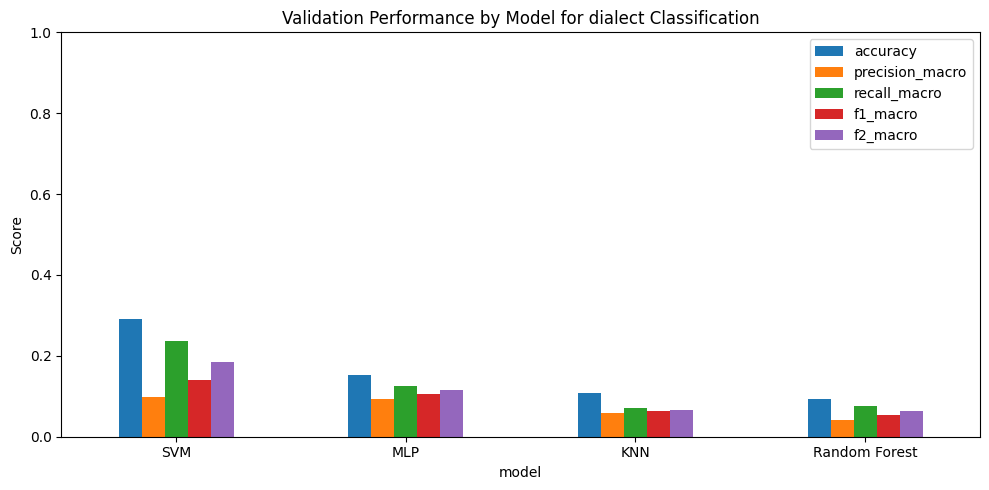


Best model for dialect classification based on macro-F1: SVM
Feature count after VarianceThreshold: 81


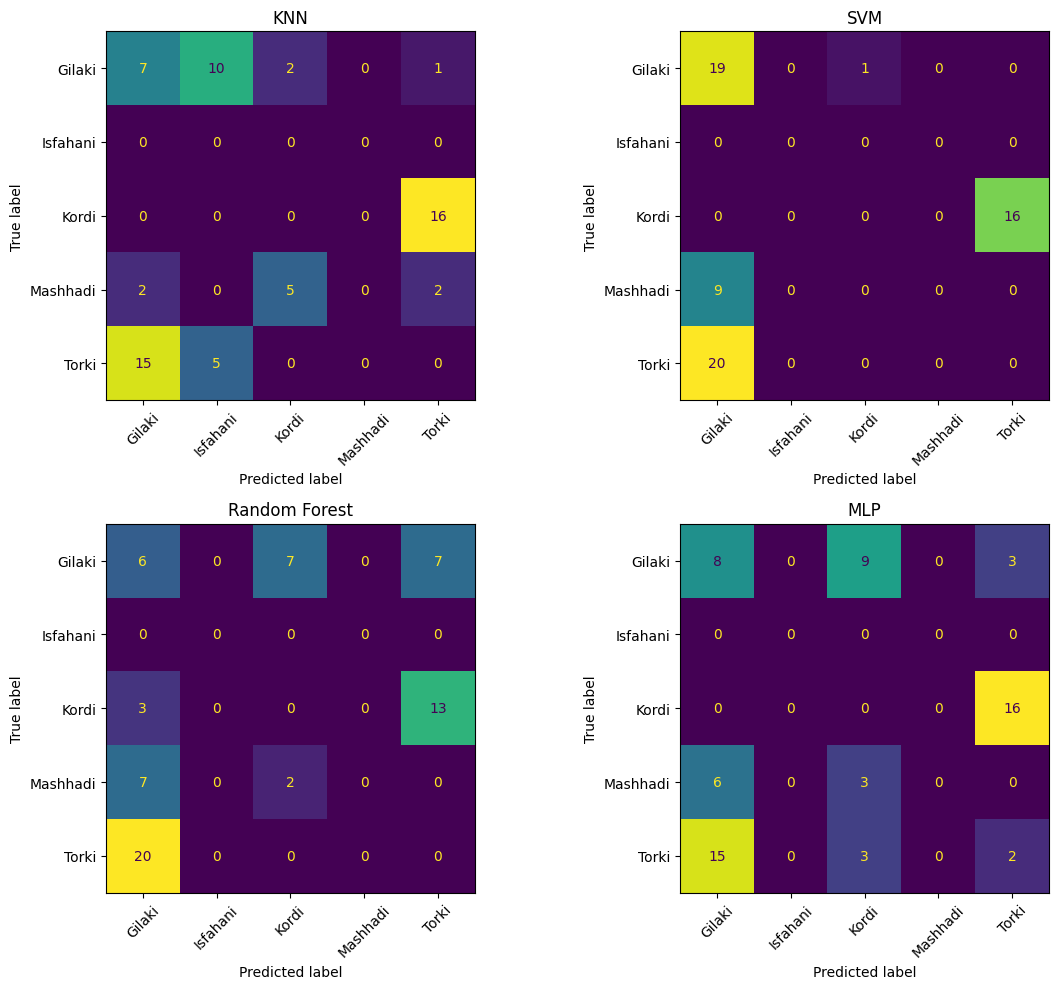


===== KNN — validation classification report for dialect =====
              precision    recall  f1-score   support

      Gilaki       0.29      0.35      0.32        20
    Isfahani       0.00      0.00      0.00         0
       Kordi       0.00      0.00      0.00        16
    Mashhadi       0.00      0.00      0.00         9
       Torki       0.00      0.00      0.00        20

    accuracy                           0.11        65
   macro avg       0.06      0.07      0.06        65
weighted avg       0.09      0.11      0.10        65


===== SVM — validation classification report for dialect =====
              precision    recall  f1-score   support

      Gilaki       0.40      0.95      0.56        20
    Isfahani       0.00      0.00      0.00         0
       Kordi       0.00      0.00      0.00        16
    Mashhadi       0.00      0.00      0.00         9
       Torki       0.00      0.00      0.00        20

    accuracy                           0.29        65
   

,accuracy,precision_macro,recall_macro,f1_macro,f2_macro
model,,,,,
SVM,0.8841,0.8888,0.8849,0.8838,0.8837
Random Forest,0.7536,0.8117,0.7567,0.7430,0.7428
MLP,0.6667,0.7982,0.6714,0.6289,0.6378
KNN,0.6232,0.7061,0.6185,0.5761,0.5877


<Figure size 1000x500 with 0 Axes>

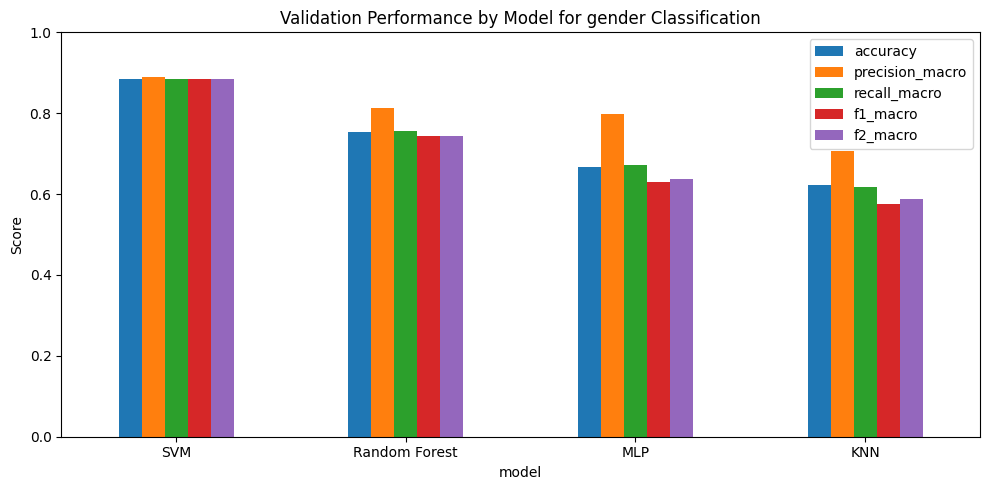


Best model for gender classification based on macro-F1: SVM
Feature count after VarianceThreshold: 81


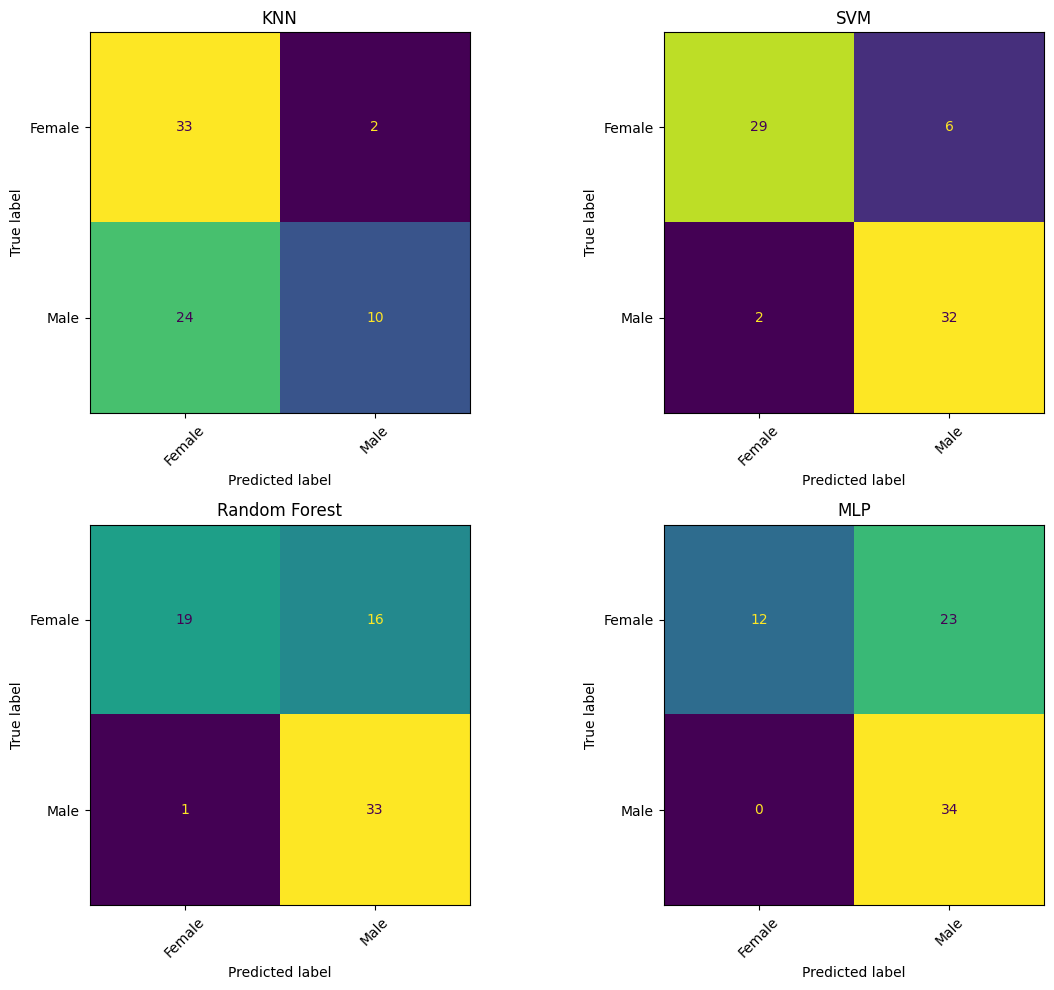


===== KNN — validation classification report for gender =====
              precision    recall  f1-score   support

      Female       0.58      0.94      0.72        35
        Male       0.83      0.29      0.43        34

    accuracy                           0.62        69
   macro avg       0.71      0.62      0.58        69
weighted avg       0.70      0.62      0.58        69


===== SVM — validation classification report for gender =====
              precision    recall  f1-score   support

      Female       0.94      0.83      0.88        35
        Male       0.84      0.94      0.89        34

    accuracy                           0.88        69
   macro avg       0.89      0.88      0.88        69
weighted avg       0.89      0.88      0.88        69


===== Random Forest — validation classification report for gender =====
              precision    recall  f1-score   support

      Female       0.95      0.54      0.69        35
        Male       0.67      0.97     

In [8]:
classification_outputs = {}

for target in target_columns:
    if target in pool_df.columns:
        classification_outputs[target] = run_classification_for_target(target)
    else:
        print(f"Target column not found and skipped: {target}")


# 5. Final Classification Summary

This cell creates a final summary of the best classification model selected for each prediction target.

The required results are retrieved from the previously created `classification_outputs` dictionary. For each target, such as `dialect` and `gender`, the code extracts:

- The name of the selected best model.
- The evaluation metrics associated with that model.

The following metrics are included in the summary:

| Metric | Description |
|---|---|
| `accuracy` | Proportion of validation samples classified correctly. |
| `precision_macro` | Unweighted mean of precision across all evaluated classes. |
| `recall_macro` | Unweighted mean of recall across all evaluated classes. |
| `f1_macro` | Unweighted mean of the class-level F1-scores. |
| `f2_macro` | Unweighted mean of the class-level F2-scores, giving more importance to recall. |

The final summary contains one row for each classification target:

| Column | Description |
|---|---|
| `target` | Classification target, such as `dialect` or `gender`. |
| `best_model` | Name of the selected best-performing model. |
| `accuracy` | Accuracy of the selected model. |
| `precision_macro` | Macro-averaged precision of the selected model. |
| `recall_macro` | Macro-averaged recall of the selected model. |
| `f1_macro` | Macro-averaged F1-score of the selected model. |
| `f2_macro` | Macro-averaged F2-score of the selected model. |

The resulting DataFrame is displayed with metric values rounded to four decimal places for readability.

Finally, the unrounded summary is exported to:

`Results/Classification/final_dialect_gender_classification_summary.csv`

This exported file provides a compact comparison of the final selected models for dialect and gender classification.


In [9]:
summary_rows = []

for target, output in classification_outputs.items():
    results_df = output["results"]
    best_model_name = output["best_model_name"]
    best_row = results_df.loc[best_model_name].to_dict()

    summary_rows.append({
        "target": target,
        "best_model": best_model_name,
        "accuracy": best_row["accuracy"],
        "precision_macro": best_row["precision_macro"],
        "recall_macro": best_row["recall_macro"],
        "f1_macro": best_row["f1_macro"],
        "f2_macro": best_row["f2_macro"]
    })

final_summary_df = pd.DataFrame(summary_rows)

display(final_summary_df.round(4))

final_summary_df.to_csv("Results/Classification/final_dialect_gender_classification_summary.csv", index=False)

print("Final summary saved to Results/Classification/final_dialect_gender_classification_summary.csv")


,target,best_model,accuracy,precision_macro,recall_macro,f1_macro,f2_macro
0,dialect,SVM,0.2923,0.0990,0.2375,0.1397,0.1855
1,gender,SVM,0.8841,0.8888,0.8849,0.8838,0.8837


Final summary saved to Results/Classification/final_dialect_gender_classification_summary.csv


# 6. Clustering Model Implementation

This section applies unsupervised clustering to the numerical features in `pool_df`. The `dialect` and `gender` labels are retained for later evaluation, while the number of dialect classes is also used as a fixed reference cluster count.

| Preprocessing step | Purpose |
|---|---|
| `VarianceThreshold` | Removes features with variance below `1e-6`. |
| `StandardScaler` | Standardizes the retained features. |
| `PCA` | Retains 90% of the total variance. |
| `Normalizer` | Applies L2 normalization to the PCA representation. |

Three clustering methods are evaluated over candidate cluster counts:

| Model | Selection and analysis |
|---|---|
| `K-Means` | Elbow inertia and Silhouette Score |
| `GMM` | Joint search over covariance type and `k`, followed by Silhouette, BIC, and AIC analysis |
| `Hierarchical` | Silhouette Score using Ward linkage |

Each model produces two clustering solutions:

| Solution | Cluster count |
|---|---|
| Silhouette-based | Best `k` selected by Silhouette Score |
| Dialect-count reference | `k` equal to the actual number of dialect labels |

The generated analysis plots are saved in the clustering results directory.


Feature pipeline: raw=81 -> after VarianceThreshold=81 -> PCA=27 dimensions
Number of training samples: 350
Number of actual dialects: 5
PCA explained variance: 90.50%


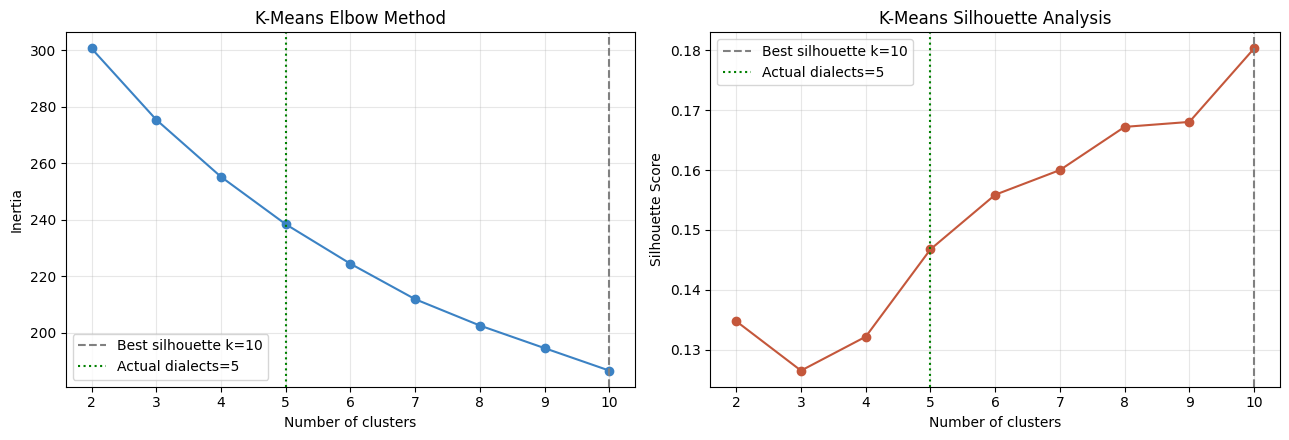

Selected GMM covariance_type='full', k=10 (silhouette=0.1761), chosen by joint search over (covariance_type, k)


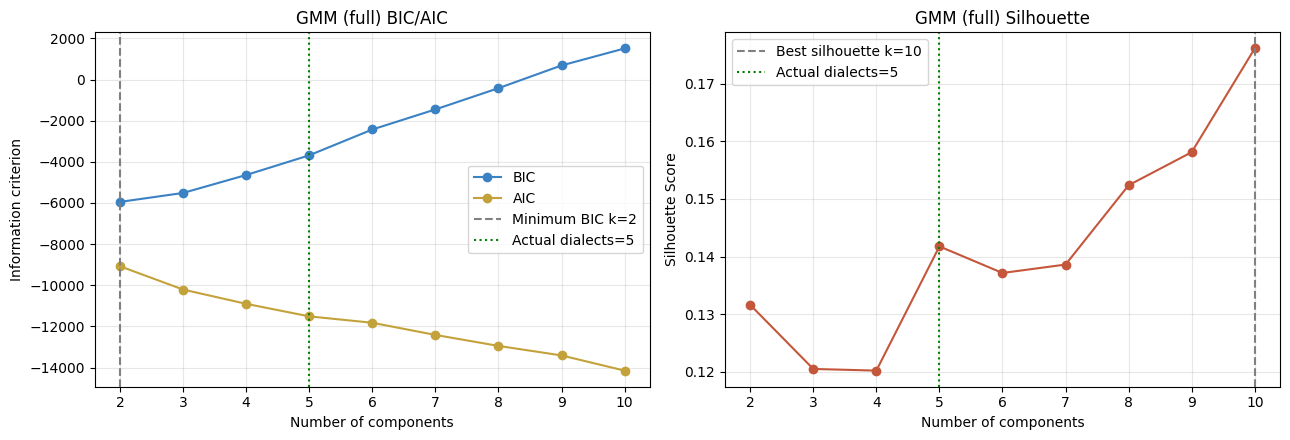

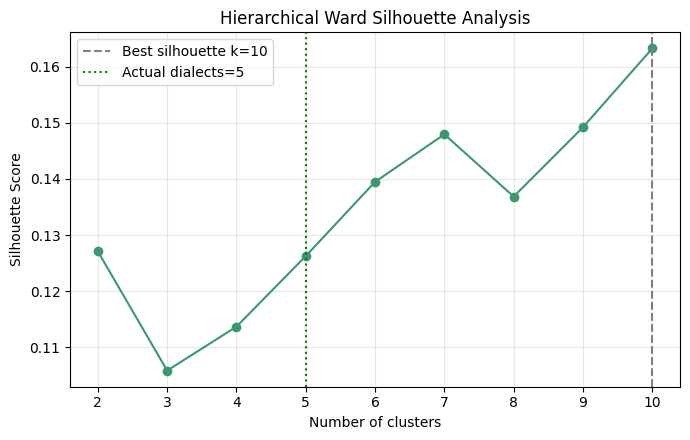

K-Means best silhouette k: 10
GMM best silhouette k: 10
GMM minimum BIC k: 2
GMM minimum AIC k: 10
Hierarchical best silhouette k: 10
Selected GMM covariance type: full


In [10]:
X_cluster_df = pool_df[FEATURE_COLUMNS].copy()
X_cluster_df = X_cluster_df.apply(pd.to_numeric, errors="coerce")

if X_cluster_df.isna().any().any():
    raise ValueError("Clustering feature matrix contains NaN values.")

if "dialect" not in pool_df.columns:
    raise ValueError("Column 'dialect' is required for clustering evaluation.")

if "gender" not in pool_df.columns:
    raise ValueError("Column 'gender' is required for clustering evaluation.")

y_dialect = pool_df["dialect"].astype(str).to_numpy()
y_gender = pool_df["gender"].astype(str).to_numpy()

n_true_dialects = len(np.unique(y_dialect))

variance_filter = VarianceThreshold(threshold=1e-6)
X_var = variance_filter.fit_transform(X_cluster_df)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_var)

pca_cluster = PCA(n_components=0.90, whiten=False, random_state=RANDOM_STATE)
X_cluster_space = pca_cluster.fit_transform(X_scaled)

print(f"Feature pipeline: raw={X_cluster_df.shape[1]} -> after VarianceThreshold={X_var.shape[1]} -> PCA={X_cluster_space.shape[1]} dimensions")

print(f"Number of training samples: {X_cluster_space.shape[0]}")
print(f"Number of actual dialects: {n_true_dialects}")
print(f"PCA explained variance: {pca_cluster.explained_variance_ratio_.sum() * 100:.2f}%")

normalizer = Normalizer(norm="l2")
X_cluster_space = normalizer.fit_transform(X_cluster_space)

k_values=list(range(2, min(10, X_cluster_space.shape[0] - 1) + 1))

inertias = []
sil_scores_kmeans=[]

for k in k_values:
    model=KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=50, max_iter=500)
    labels = model.fit_predict(X_cluster_space)
    inertias.append(model.inertia_)
    sil_scores_kmeans.append(silhouette_score(X_cluster_space, labels))

k_sil_kmeans=k_values[int(np.argmax(sil_scores_kmeans))]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(k_values, inertias, "o-", color="#3B82C4")
axes[0].axvline(k_sil_kmeans, color="gray", linestyle="--", label=f"Best silhouette k={k_sil_kmeans}")
axes[0].axvline(n_true_dialects, color="green", linestyle=":", linewidth=1.5, label=f"Actual dialects={n_true_dialects}")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")
axes[0].set_title("K-Means Elbow Method")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(k_values, sil_scores_kmeans, "o-", color="#C4573B")
axes[1].axvline(k_sil_kmeans, color="gray", linestyle="--", label=f"Best silhouette k={k_sil_kmeans}")
axes[1].axvline(n_true_dialects, color="green", linestyle=":", linewidth=1.5, label=f"Actual dialects={n_true_dialects}")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("K-Means Silhouette Analysis")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CLUSTERING_DIR, "K-Means Silhouette Analysis.png"), dpi=300, bbox_inches="tight")
plt.show()

covariance_candidates = ["tied", "diag", "full", "spherical"]

best_silhouette=-1.0
gmm_covariance_type = None
k_sil_gmm=None

for covariance_type in covariance_candidates:
    for k in k_values:
        model = GaussianMixture(n_components=k, covariance_type=covariance_type, random_state=RANDOM_STATE, n_init=10, reg_covar=1e-4)

        labels=model.fit_predict(X_cluster_space)

        if len(np.unique(labels)) > 1:
            score = silhouette_score(X_cluster_space, labels)
            if score > best_silhouette:
                best_silhouette=score
                gmm_covariance_type = covariance_type
                k_sil_gmm=k

print(f"Selected GMM covariance_type='{gmm_covariance_type}', k={k_sil_gmm} (silhouette={best_silhouette:.4f}), chosen by joint search over (covariance_type, k)")

gmm_bic=[]
gmm_aic = []
gmm_silhouette=[]

for k in k_values:
    model=GaussianMixture(n_components=k, covariance_type=gmm_covariance_type, random_state=RANDOM_STATE, n_init=10, reg_covar=1e-4)

    labels = model.fit_predict(X_cluster_space)

    gmm_bic.append(model.bic(X_cluster_space))
    gmm_aic.append(model.aic(X_cluster_space))

    if len(np.unique(labels)) > 1:
        gmm_silhouette.append(silhouette_score(X_cluster_space, labels))
    else:
        gmm_silhouette.append(-1)

k_bic_gmm=k_values[int(np.argmin(gmm_bic))]
k_aic_gmm = k_values[int(np.argmin(gmm_aic))]
k_sil_gmm=k_values[int(np.argmax(gmm_silhouette))]

fig, axes=plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(k_values, gmm_bic, "o-", label="BIC", color="#3B82C4")
axes[0].plot(k_values, gmm_aic, "o-", label="AIC", color="#C4A23B")
axes[0].axvline(k_bic_gmm, color="gray", linestyle="--", label=f"Minimum BIC k={k_bic_gmm}")
axes[0].axvline(n_true_dialects, color="green", linestyle=":", linewidth=1.5, label=f"Actual dialects={n_true_dialects}")
axes[0].set_xlabel("Number of components")
axes[0].set_ylabel("Information criterion")
axes[0].set_title(f"GMM ({gmm_covariance_type}) BIC/AIC")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(k_values, gmm_silhouette, "o-", color="#C4573B")
axes[1].axvline(k_sil_gmm, color="gray", linestyle="--", label=f"Best silhouette k={k_sil_gmm}")
axes[1].axvline(n_true_dialects, color="green", linestyle=":", linewidth=1.5, label=f"Actual dialects={n_true_dialects}")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title(f"GMM ({gmm_covariance_type}) Silhouette")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CLUSTERING_DIR, f"GMM ({gmm_covariance_type}) Silhouette.png"), dpi=300, bbox_inches="tight")
plt.show()

sil_scores_hierarchical=[]

for k in k_values:
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")

    labels=model.fit_predict(X_cluster_space)
    sil_scores_hierarchical.append(silhouette_score(X_cluster_space, labels))

k_sil_hierarchical = k_values[int(np.argmax(sil_scores_hierarchical))]

fig, ax=plt.subplots(figsize=(7, 4.5))

ax.plot(k_values, sil_scores_hierarchical, "o-", color="#3B9970")
ax.axvline(k_sil_hierarchical, color="gray", linestyle="--", label=f"Best silhouette k={k_sil_hierarchical}")
ax.axvline(n_true_dialects, color="green", linestyle=":", linewidth=1.5, label=f"Actual dialects={n_true_dialects}")
ax.set_xlabel("Number of clusters")
ax.set_ylabel("Silhouette Score")
ax.set_title("Hierarchical Ward Silhouette Analysis")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CLUSTERING_DIR, "Hierarchical Ward Silhouette Analysis.png"), dpi=300, bbox_inches="tight")
plt.show()

kmeans_unsup=KMeans(n_clusters=k_sil_kmeans, random_state=RANDOM_STATE, n_init=50, max_iter=500)
kmeans_unsup_labels = kmeans_unsup.fit_predict(X_cluster_space)

gmm_unsup = GaussianMixture(n_components=k_sil_gmm, covariance_type=gmm_covariance_type, random_state=RANDOM_STATE, n_init=10, reg_covar=1e-4)
gmm_unsup_labels=gmm_unsup.fit_predict(X_cluster_space)

hierarchical_unsup = AgglomerativeClustering(n_clusters=k_sil_hierarchical, linkage="ward")
hierarchical_unsup_labels=hierarchical_unsup.fit_predict(X_cluster_space)

kmeans_true=KMeans(n_clusters=n_true_dialects, random_state=RANDOM_STATE, n_init=50, max_iter=500)
kmeans_true_labels = kmeans_true.fit_predict(X_cluster_space)

gmm_true = GaussianMixture(n_components=n_true_dialects, covariance_type=gmm_covariance_type, random_state=RANDOM_STATE, n_init=10, reg_covar=1e-4)
gmm_true_labels=gmm_true.fit_predict(X_cluster_space)

hierarchical_true = AgglomerativeClustering(n_clusters=n_true_dialects, linkage="ward")
hierarchical_true_labels=hierarchical_true.fit_predict(X_cluster_space)

print(f"K-Means best silhouette k: {k_sil_kmeans}")
print(f"GMM best silhouette k: {k_sil_gmm}")
print(f"GMM minimum BIC k: {k_bic_gmm}")
print(f"GMM minimum AIC k: {k_aic_gmm}")
print(f"Hierarchical best silhouette k: {k_sil_hierarchical}")
print(f"Selected GMM covariance type: {gmm_covariance_type}")


# 7. Clustering Metrics Calculation

In this section, the clustering results from the previous part are evaluated.

The evaluation is done for three clustering models:

| Model | Description |
|---|---|
| `K-Means` | Evaluated on the L2-normalized PCA feature space. |
| `GMM` | Evaluated on the PCA-reduced feature space. |
| `Hierarchical` | Evaluated on the PCA-reduced feature space. |

Two sets of clustering results are compared:

| Result type | Description |
|---|---|
| Unsupervised silhouette-based k | Uses the best `k` selected by Silhouette Score in Section 1. |
| Actual dialect count k | Uses `k = number of real dialects` for direct comparison with dialect labels. |

The following metrics are calculated for each model:

| Metric | Purpose |
|---|---|
| `Silhouette Score` | Internal clustering metric that measures how compact and separated the clusters are. It does not use true labels. |
| `ARI Dialect` | Measures how well the clusters match the real dialect labels. |
| `NMI Dialect` | Measures the shared information between clusters and real dialect labels. |
| `ARI Gender` | Measures how much the clusters align with gender labels. |
| `NMI Gender` | Measures the shared information between clusters and gender labels. |

The true `dialect` and `gender` labels are used only for evaluation after clustering.
They are not used during clustering or during unsupervised `k` selection.

The code first creates two summary tables:

| Table | Content |
|---|---|
| `summary_unsupervised` | Metrics for models using the silhouette-selected `k`. |
| `summary_true_k` | Metrics for models using the actual number of dialects. |

Then, the best model in each setting is selected based on `NMI Dialect`.

Finally, cluster composition heatmaps are plotted using `pd.crosstab`.
These plots show how each cluster is distributed across the real dialect and gender labels.
This helps interpret whether the clusters mainly represent dialect differences, gender differences,
or mixed speaker-related patterns.


Unsupervised Model Selection Results


,Model,Selection,k,Silhouette,ARI Dialect,NMI Dialect,ARI Gender,NMI Gender
0,K-Means,Unsupervised silhouette-based k,10,0.1803,0.1652,0.3848,0.1620,0.3242
1,GMM,Unsupervised silhouette-based k,10,0.1761,0.1635,0.3760,0.1557,0.3140
2,Hierarchical,Unsupervised silhouette-based k,10,0.1633,0.1543,0.3639,0.1523,0.3070


Comparison Using Actual Number of Dialects


,Model,Selection,k,Silhouette,ARI Dialect,NMI Dialect,ARI Gender,NMI Gender
0,K-Means,Comparison using actual dialect count,5,0.1468,0.1664,0.2679,0.1900,0.2101
1,GMM,Comparison using actual dialect count,5,0.1418,0.1998,0.2926,0.1995,0.2766
2,Hierarchical,Comparison using actual dialect count,5,0.1263,0.1190,0.2343,0.2025,0.2474


Best unsupervised model by NMI Dialect: K-Means (k=10, NMI=0.3848, ARI=0.1652, Silhouette=0.1803)
Best k=5 model by NMI Dialect: GMM (NMI=0.2926, ARI=0.1998, Silhouette=0.1418)


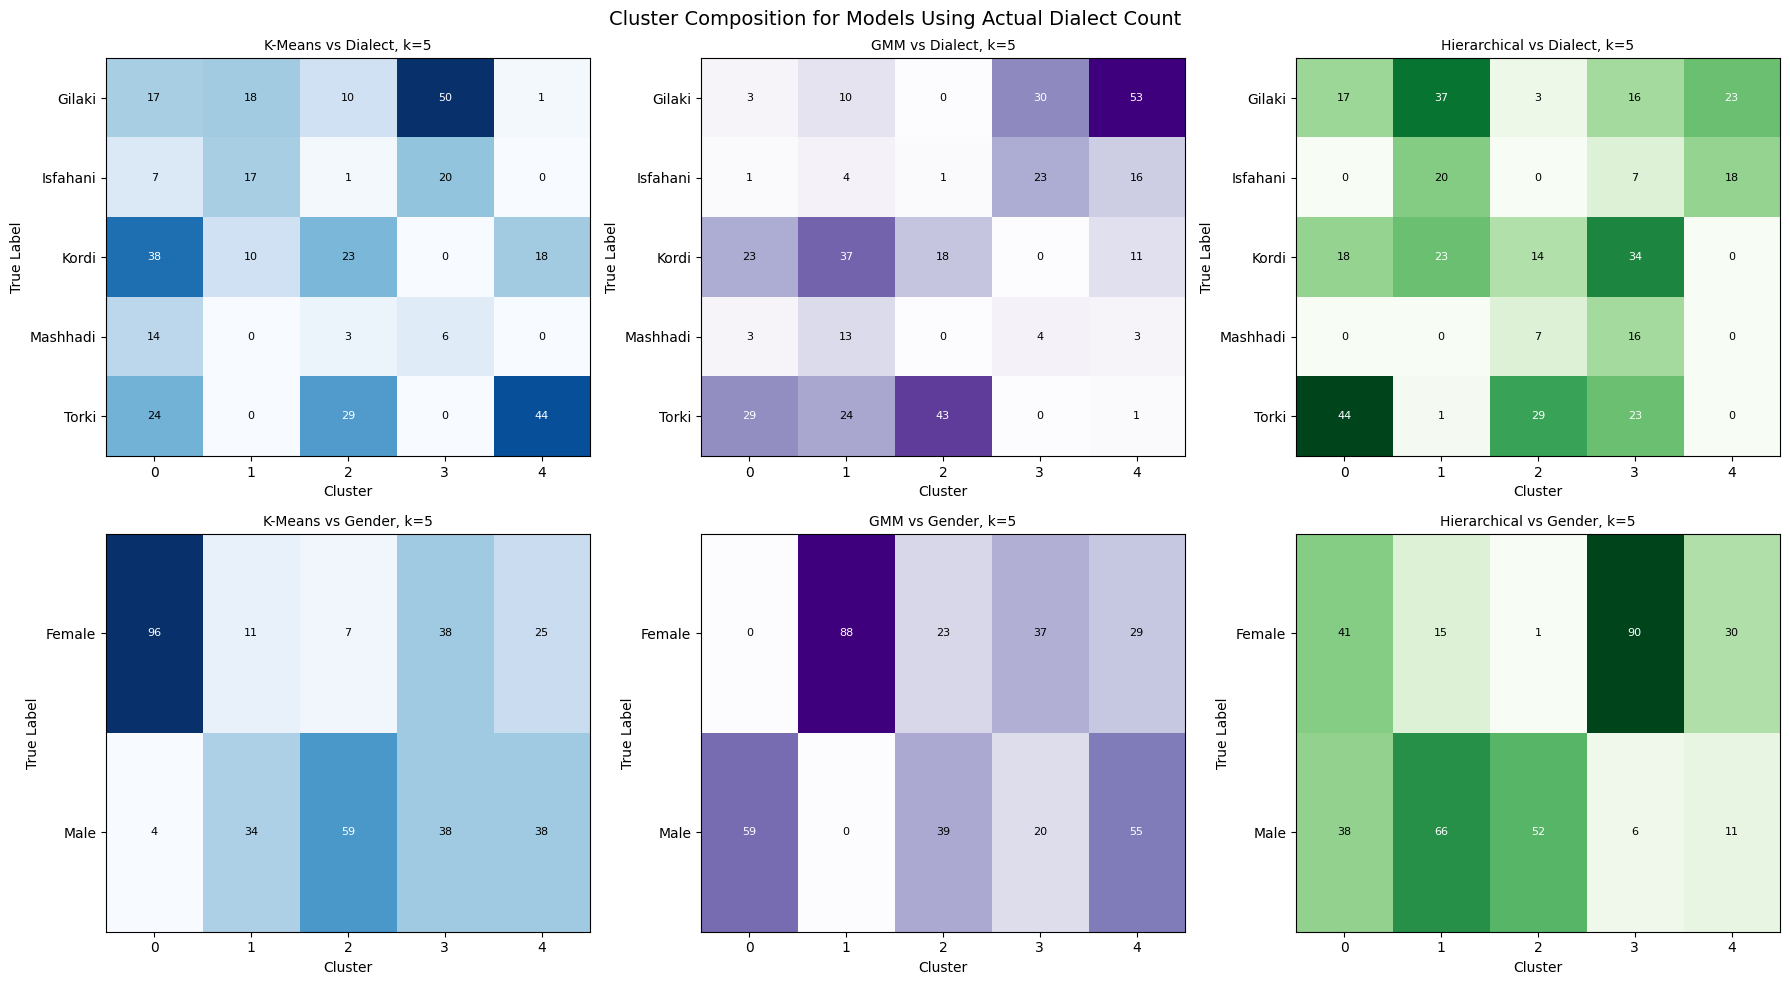

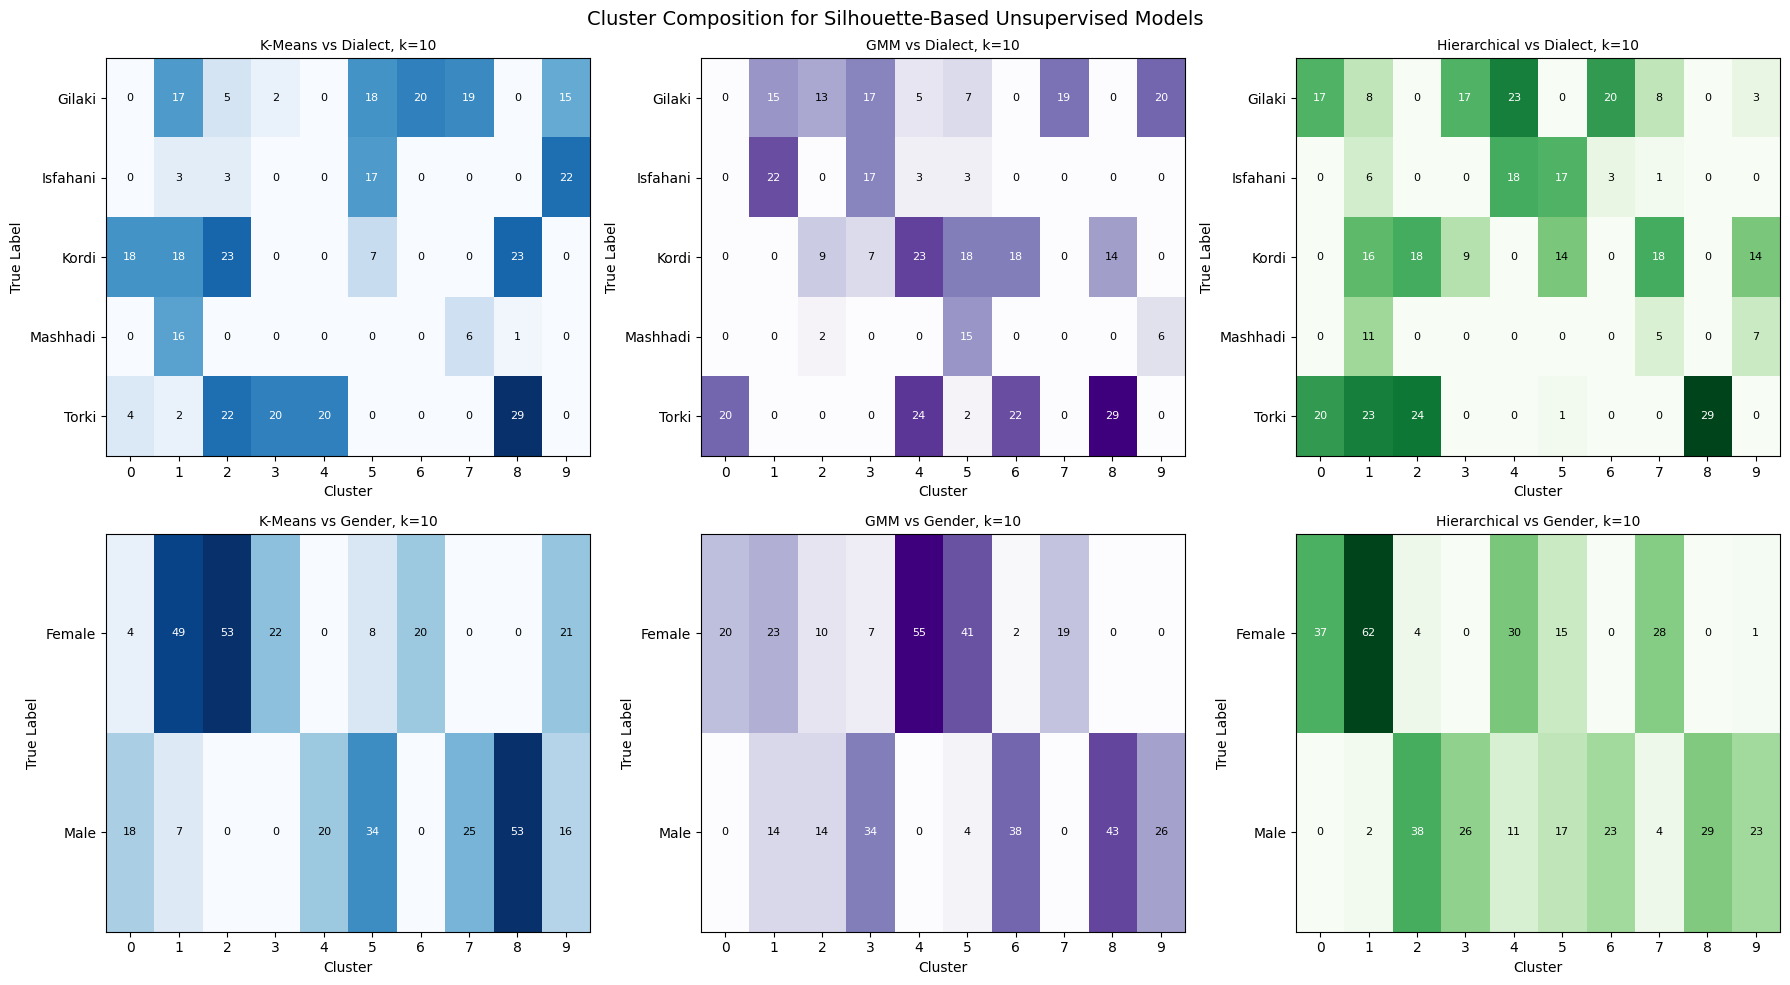

In [11]:

def evaluate_clustering(name, labels, k, selection_type, space=X_cluster_space):
    unique_labels = np.unique(labels)
    return {"Model": name, "Selection": selection_type, "k": k, "Silhouette": silhouette_score(space, labels) if len(unique_labels) > 1 else np.nan, "ARI Dialect": adjusted_rand_score(y_dialect, labels), "NMI Dialect": normalized_mutual_info_score(y_dialect, labels), "ARI Gender": adjusted_rand_score(y_gender, labels), "NMI Gender": normalized_mutual_info_score(y_gender, labels)}

model_spaces = {"K-Means": X_cluster_space, "GMM": X_cluster_space, "Hierarchical": X_cluster_space}

unsupervised_models  =  {"K-Means": (kmeans_unsup_labels, k_sil_kmeans), "GMM": (gmm_unsup_labels, k_sil_gmm), "Hierarchical": (hierarchical_unsup_labels, k_sil_hierarchical)}

true_k_models = {"K-Means": (kmeans_true_labels, n_true_dialects), "GMM": (gmm_true_labels, n_true_dialects), "Hierarchical": (hierarchical_true_labels, n_true_dialects)}

unsupervised_rows = [evaluate_clustering(name=name, labels=labels, k=k, selection_type="Unsupervised silhouette-based k", space=model_spaces[name]) for name, (labels, k) in unsupervised_models.items()]

true_k_rows = [evaluate_clustering(name=name, labels=labels, k=k, selection_type="Comparison using actual dialect count", space=model_spaces[name]) for name, (labels, k) in true_k_models.items()]

summary_unsupervised = pd.DataFrame(unsupervised_rows).round(4)
summary_true_k  =  pd.DataFrame(true_k_rows).round(4)

print("Unsupervised Model Selection Results")
display(summary_unsupervised)
summary_unsupervised.to_csv(os.path.join(CLUSTERING_DIR, "summary_unsupervised.csv"), index=False)

print("Comparison Using Actual Number of Dialects")
display(summary_true_k)
summary_true_k.to_csv(os.path.join(CLUSTERING_DIR, "summary_true_k.csv"), index=False)

combined_summary = pd.concat([summary_unsupervised, summary_true_k], axis=0).reset_index(drop=True)

best_unsupervised_row = combined_summary[combined_summary["Selection"] == "Unsupervised silhouette-based k"].sort_values(by="NMI Dialect", ascending=False).iloc[0]

best_true_k_row  =  combined_summary[combined_summary["Selection"] == "Comparison using actual dialect count"].sort_values(by="NMI Dialect", ascending=False).iloc[0]

print(f"Best unsupervised model by NMI Dialect: {best_unsupervised_row['Model']} (k={int(best_unsupervised_row['k'])}, NMI={best_unsupervised_row['NMI Dialect']:.4f}, ARI={best_unsupervised_row['ARI Dialect']:.4f}, Silhouette={best_unsupervised_row['Silhouette']:.4f})")

print(f"Best k={n_true_dialects} model by NMI Dialect: {best_true_k_row['Model']} (NMI={best_true_k_row['NMI Dialect']:.4f}, ARI={best_true_k_row['ARI Dialect']:.4f}, Silhouette={best_true_k_row['Silhouette']:.4f})")

k_values_selected = [k_sil_kmeans, k_sil_gmm, k_sil_hierarchical]

def plot_cluster_composition(ax, true_labels, cluster_labels, title, cmap):
    table = pd.crosstab(pd.Series(true_labels, name="True Label"), pd.Series(cluster_labels, name="Cluster"))
    image = ax.imshow(table.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(table.columns)
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("True Label")
    ax.set_title(title, fontsize=10)
    threshold = table.values.max() / 2 if table.values.size > 0 else 0
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            value = table.iloc[i, j]
            ax.text(j, i, str(value), ha="center", va="center", color="white" if value > threshold else "black", fontsize=8)
    return image

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
model_colors  =  ["Blues", "Purples", "Greens"]

for column, (name, (labels, k)) in enumerate(true_k_models.items()):
    plot_cluster_composition(axes[0, column], y_dialect, labels, f"{name} vs Dialect, k={k}", model_colors[column])
    plot_cluster_composition(axes[1, column], y_gender, labels, f"{name} vs Gender, k={k}", model_colors[column])

fig.suptitle("Cluster Composition for Models Using Actual Dialect Count", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(CLUSTERING_DIR,"Cluster Composition for Models Using Actual Dialect Count.png"), dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for column, (name, (labels, k)) in enumerate(unsupervised_models.items()):
    plot_cluster_composition(axes[0, column], y_dialect, labels, f"{name} vs Dialect, k={k}", model_colors[column])
    plot_cluster_composition(axes[1, column], y_gender, labels, f"{name} vs Gender, k={k}", model_colors[column])

fig.suptitle("Cluster Composition for Silhouette-Based Unsupervised Models", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(CLUSTERING_DIR,"Cluster Composition for Silhouette-Based Unsupervised Models.png"), dpi=300, bbox_inches="tight")
plt.show()


# 8. Dimensionality Reduction and 2D Visualization

In this section, the feature space is projected into two dimensions for visual analysis.

The 2D projections are created from `X_var`, which is the standardized and variance-filtered feature space.
These visualizations are used only for interpretation and presentation. They are not used for training the
clustering models.

Two dimensionality reduction methods are used:

| Method | Purpose |
|---|---|
| `PCA(n_components=2)` | Creates a simple linear 2D projection and reports the explained variance. |
| `t-SNE(n_components=2)` | Creates a nonlinear 2D projection that can show local structure more clearly. |

The t-SNE perplexity is selected automatically based on the number of training samples:

| Parameter | Description |
|---|---|
| `tsne_perplexity` | Set between 5 and 30, depending on the dataset size. |

Two helper functions are used for plotting:

| Function | Purpose |
|---|---|
| `plot_true_labels` | Plots the 2D points using the real dialect or gender labels. |
| `plot_cluster_labels` | Plots the 2D points using the predicted cluster labels. |

Four visualization figures are generated:

| Figure | Content |
|---|---|
| PCA with actual dialect count | Shows true dialect, true gender, and the three clustering models with `k = number of dialects`. |
| t-SNE with actual dialect count | Shows the same information using the t-SNE projection. |
| PCA with silhouette-based k | Shows true dialect, true gender, and the three clustering models using their best silhouette-selected `k`. |
| t-SNE with silhouette-based k | Shows the same information using the t-SNE projection. |

Each figure contains five panels:

| Panel | Shows |
|---|---|
| 1 | True dialect labels. |
| 2 | True gender labels. |
| 3 | K-Means cluster labels. |
| 4 | GMM cluster labels. |
| 5 | Hierarchical cluster labels. |

These plots help visually compare the real labels with the discovered clusters.
They also help show whether the clustering structure is closer to dialect, gender, or mixed speaker-related
patterns.


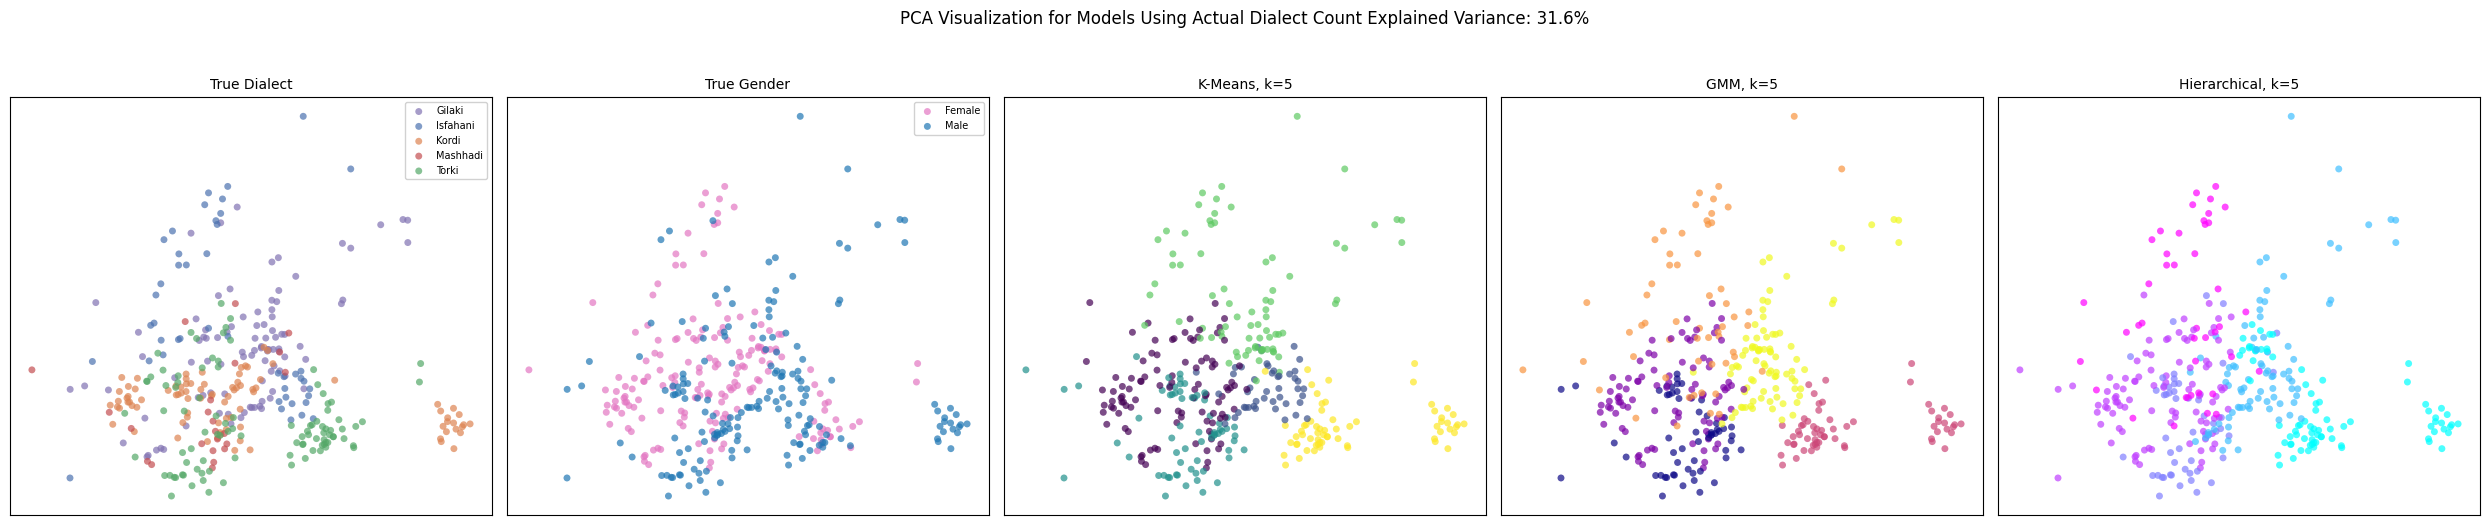

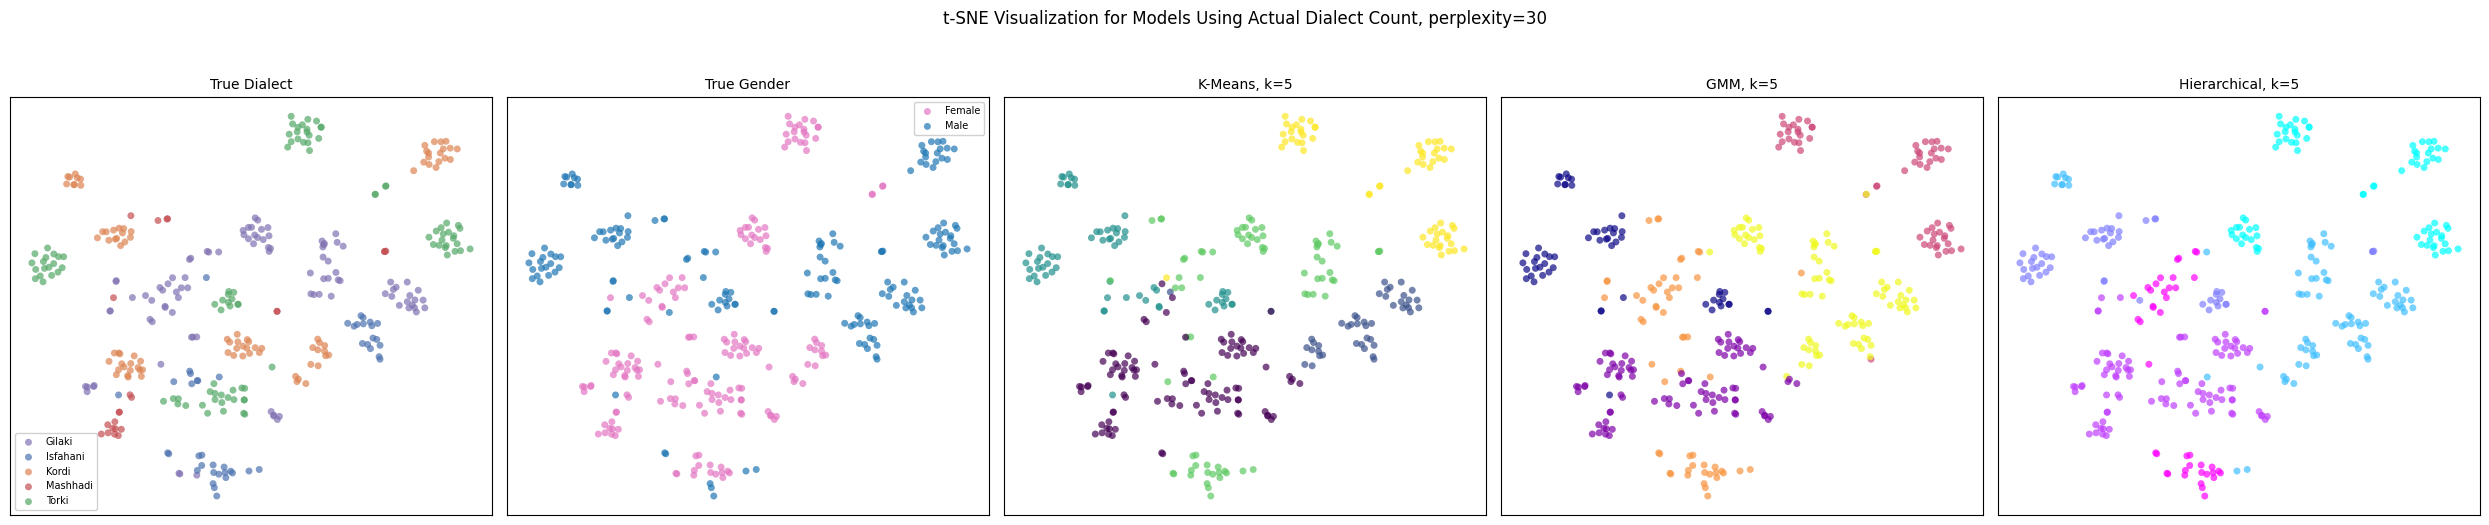

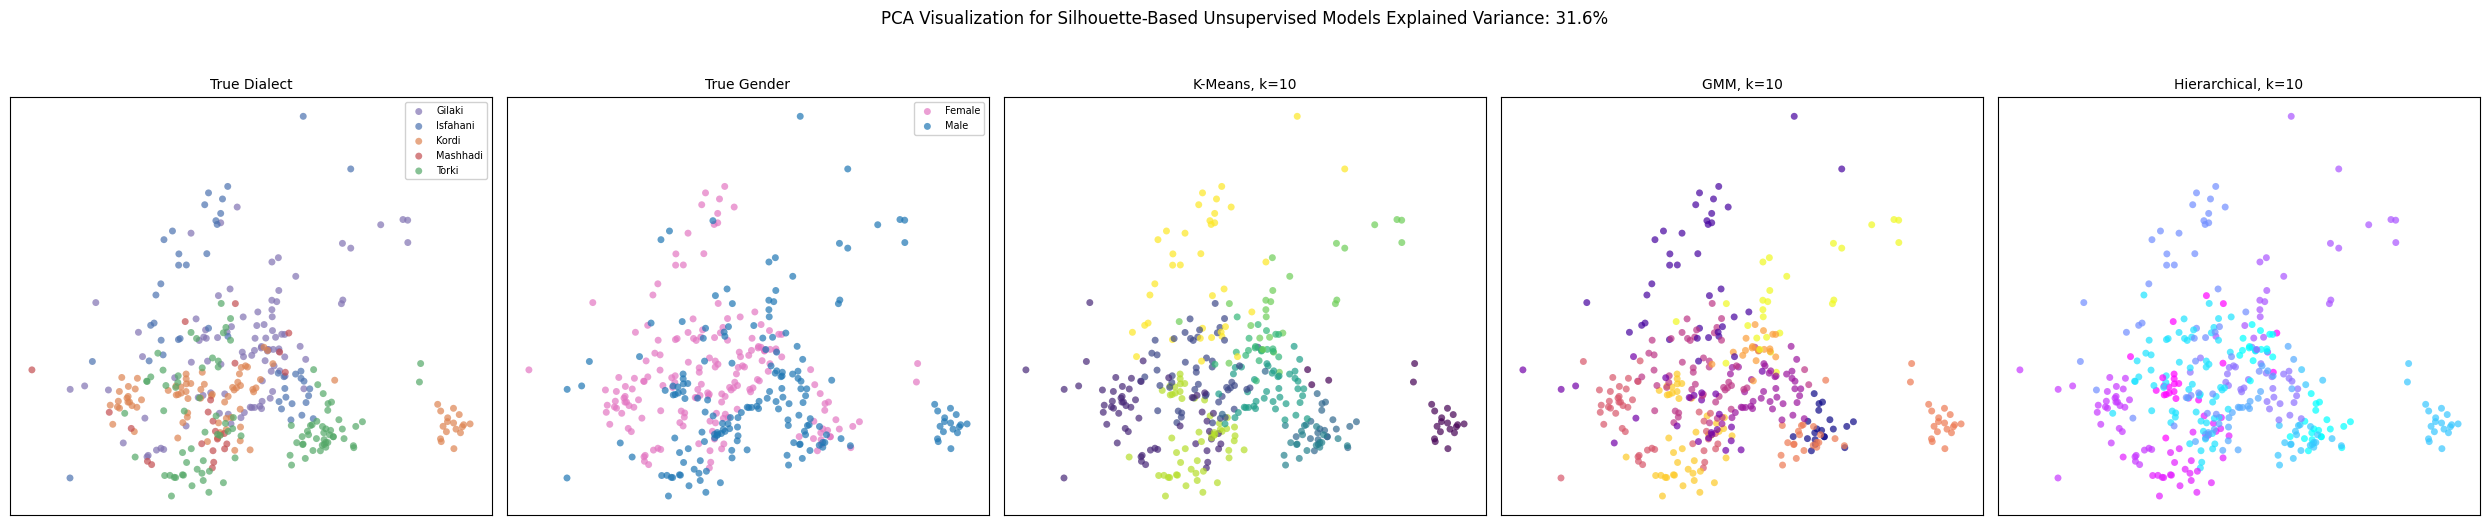

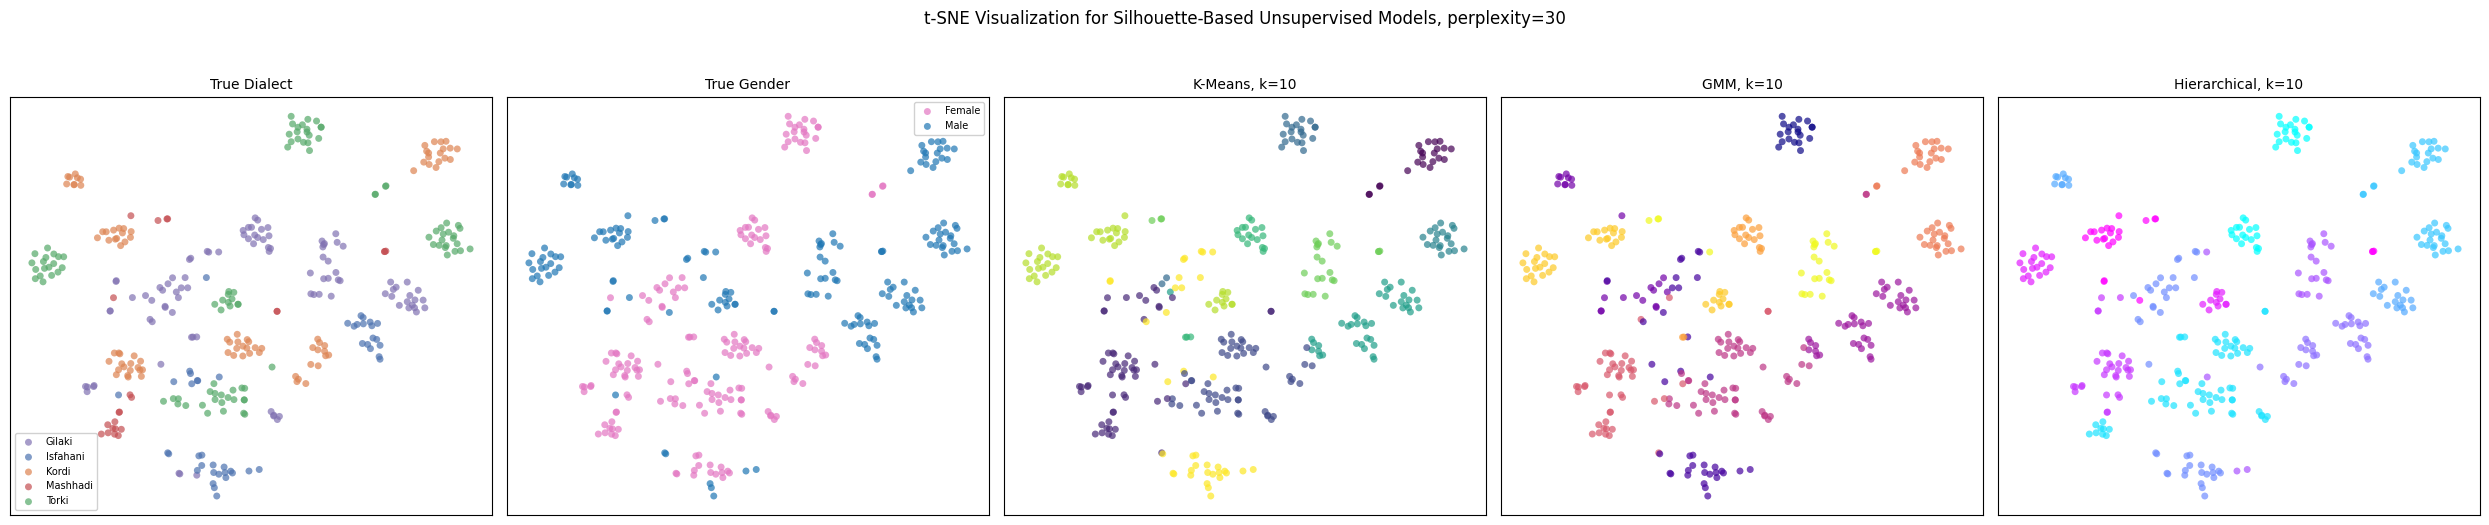

In [12]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)

X_pca_2d = pca_2d.fit_transform(X_scaled)

tsne_perplexity = min(30, max(5, (X_scaled.shape[0] - 1) // 3))

tsne_2d = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=tsne_perplexity, init="pca", learning_rate="auto")

X_tsne_2d = tsne_2d.fit_transform(X_scaled)


dialect_colors = {
    "Isfahani": "#4C72B0",
    "Torki": "#55A868",
    "Kordi": "#DD8452",
    "Mashhadi": "#C44E52",
    "Gilaki": "#8172B2"
}

gender_colors= {
    "Female": "#E377C2",
    "Male": "#1F77B4"
}

def plot_true_labels(ax, embedding, labels, color_map, title):
    labels=np.asarray(labels)
    unique_labels = np.unique(labels)
    for label in unique_labels:
        mask=labels == label
        color = color_map.get(label, "#777777")
        ax.scatter(embedding[mask, 0], embedding[mask, 1], c=color, label=str(label), alpha=0.7, s=25, edgecolors="none")
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(fontsize=7, loc="best", framealpha=0.9)

def plot_cluster_labels(ax, embedding, labels, title, cmap):
    ax.scatter(embedding[:, 0], embedding[:, 1], c=labels, cmap=cmap, alpha=0.7, s=25, edgecolors="none")
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

fig, axes=plt.subplots(1, 5, figsize=(25, 5))

plot_true_labels(axes[0], X_pca_2d, y_dialect, dialect_colors, "True Dialect")
plot_true_labels(axes[1], X_pca_2d, y_gender, gender_colors, "True Gender")
plot_cluster_labels(axes[2], X_pca_2d, kmeans_true_labels, f"K-Means, k={n_true_dialects}", "viridis")
plot_cluster_labels(axes[3], X_pca_2d, gmm_true_labels, f"GMM, k={n_true_dialects}", "plasma")
plot_cluster_labels(axes[4], X_pca_2d, hierarchical_true_labels, f"Hierarchical, k={n_true_dialects}", "cool")

fig.suptitle("PCA Visualization for Models Using Actual Dialect Count " + f"Explained Variance: {pca_2d.explained_variance_ratio_.sum() * 100:.1f}%", y=1.04)

plt.tight_layout()
fig.savefig(os.path.join(CLUSTERING_DIR,f"PCA_Actual_Dialect_Count_Explained_Variance_{pca_2d.explained_variance_ratio_.sum() * 100:.1f}.png"), dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

plot_true_labels(axes[0], X_tsne_2d, y_dialect, dialect_colors, "True Dialect")
plot_true_labels(axes[1], X_tsne_2d, y_gender, gender_colors, "True Gender")
plot_cluster_labels(axes[2], X_tsne_2d, kmeans_true_labels, f"K-Means, k={n_true_dialects}", "viridis")
plot_cluster_labels(axes[3], X_tsne_2d, gmm_true_labels, f"GMM, k={n_true_dialects}", "plasma")
plot_cluster_labels(axes[4], X_tsne_2d, hierarchical_true_labels, f"Hierarchical, k={n_true_dialects}", "cool")

fig.suptitle(f"t-SNE Visualization for Models Using Actual Dialect Count, perplexity={tsne_perplexity}", y=1.04)

plt.tight_layout()
fig.savefig(os.path.join(CLUSTERING_DIR,f"tSNE_Actual_Dialect_Count_Perplexity_{tsne_perplexity}.png"), dpi=300, bbox_inches="tight")
plt.show()

fig, axes=plt.subplots(1, 5, figsize=(25, 5))

plot_true_labels(axes[0], X_pca_2d, y_dialect, dialect_colors, "True Dialect")
plot_true_labels(axes[1], X_pca_2d, y_gender, gender_colors, "True Gender")
plot_cluster_labels(axes[2], X_pca_2d, kmeans_unsup_labels, f"K-Means, k={k_sil_kmeans}", "viridis")
plot_cluster_labels(axes[3], X_pca_2d, gmm_unsup_labels, f"GMM, k={k_sil_gmm}", "plasma")
plot_cluster_labels(axes[4], X_pca_2d, hierarchical_unsup_labels, f"Hierarchical, k={k_sil_hierarchical}", "cool")

fig.suptitle("PCA Visualization for Silhouette-Based Unsupervised Models " + f"Explained Variance: {pca_2d.explained_variance_ratio_.sum() * 100:.1f}%", y=1.04)

plt.tight_layout()
fig.savefig(os.path.join(CLUSTERING_DIR,f"PCA_Silhouette_Based_Unsupervised_Models_Explained_Variance_{pca_2d.explained_variance_ratio_.sum() * 100:.1f}.png"), dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

plot_true_labels(axes[0], X_tsne_2d, y_dialect, dialect_colors, "True Dialect")
plot_true_labels(axes[1], X_tsne_2d, y_gender, gender_colors, "True Gender")
plot_cluster_labels(axes[2], X_tsne_2d, kmeans_unsup_labels, f"K-Means, k={k_sil_kmeans}", "viridis")
plot_cluster_labels(axes[3], X_tsne_2d, gmm_unsup_labels, f"GMM, k={k_sil_gmm}", "plasma")
plot_cluster_labels(axes[4], X_tsne_2d, hierarchical_unsup_labels, f"Hierarchical, k={k_sil_hierarchical}", "cool")

fig.suptitle(f"t-SNE Visualization for Silhouette-Based Unsupervised Models, perplexity={tsne_perplexity}", y=1.04)

plt.tight_layout()
fig.savefig(os.path.join(CLUSTERING_DIR,f"tSNE_Silhouette_Based_Unsupervised_Models_Perplexity_{tsne_perplexity}.png"), dpi=300, bbox_inches="tight")
plt.show()


# 9. Save Selected League Models (.joblib)

This cell saves the final selected models required for the league submission.  
It exports the best available models for dialect classification, gender classification, and clustering into the final submission directory.

For the classification tasks, the saved models are complete fitted `scikit-learn` pipelines. Each pipeline contains the fitted preprocessing steps and the selected best estimator, so the model can be reloaded and used directly without rebuilding preprocessing manually.

For the clustering task, the final selected clustering result is taken from `best_true_k_row`. The code verifies that the selected clustering method is `K-Means` and that the selected number of clusters matches the actual number of dialects. Then, it saves a complete fitted clustering pipeline containing preprocessing, dimensionality reduction, normalization, and the final K-Means model.

| Output File | Description |
|---|---|
| `dialect_model.joblib` | Fitted pipeline for the selected dialect classification model. |
| `gender_model.joblib` | Fitted pipeline for the selected gender classification model. |
| `clustering_model.joblib` | Fitted pipeline for the final K-Means clustering model. |

| Classification Pipeline Step | Purpose |
|---|---|
| `to_numpy` | Converts input data into a NumPy array. |
| `variance_filter` | Applies the fitted variance-based feature selection step. |
| `scaler` | Applies the fitted scaling step. |
| `model` | Applies the selected fitted classification model. |

| Clustering Pipeline Step | Purpose |
|---|---|
| `to_numpy` | Converts input data into a NumPy array. |
| `variance_filter` | Applies the fitted variance-based feature selection step. |
| `scaler` | Applies the fitted scaling step. |
| `pca` | Projects the features into the fitted PCA space. |
| `normalizer` | Normalizes the transformed feature vectors. |
| `model` | Applies the final fitted K-Means clustering model. |

| Validation Step | Purpose |
|---|---|
| Clustering model check | Ensures that the selected clustering model is K-Means. |
| Cluster-count check | Ensures that the selected number of clusters matches the true number of dialects. |
| Reload validation | Reloads each saved `.joblib` file to confirm successful serialization. |
| File listing | Displays all generated model files and their sizes. |

At the end, the cell prints the export directory, saved model paths, selected model names, reload validation results, and the final list of generated `.joblib` model files.


In [13]:
print("=" * 80)
print("CELL 9 — SAVE SELECTED LEAGUE MODELS")
print("=" * 80)

print(f"Final export directory:\n{FINAL_EXPORT_DIR}\n")

dialect_model_path = None
gender_model_path = None
clustering_model_path = None

if "dialect" in classification_outputs:
    dialect_output = classification_outputs["dialect"]

    dialect_model_pipeline = Pipeline([
        ("to_numpy", FunctionTransformer(np.asarray, validate=False)),
        ("model", dialect_output["best_model"])
    ])

    dialect_model_path = os.path.join(FINAL_EXPORT_DIR, "dialect_model.joblib")
    joblib.dump(dialect_model_pipeline, dialect_model_path)

    print(f"Saved: {dialect_model_path}")
    print("Best dialect model:", dialect_output["best_model_name"])
else:
    print("Dialect classification output not available. Skipped.")

if "gender" in classification_outputs:
    gender_output = classification_outputs["gender"]

    gender_model_pipeline = Pipeline([
        ("to_numpy", FunctionTransformer(np.asarray, validate=False)),
        ("model", gender_output["best_model"])
    ])

    gender_model_path = os.path.join(FINAL_EXPORT_DIR, "gender_model.joblib")
    joblib.dump(gender_model_pipeline, gender_model_path)

    print(f"\nSaved: {gender_model_path}")
    print("Best gender model:", gender_output["best_model_name"])
else:
    print("Gender classification output not available. Skipped.")


# Select the best clustering model among models evaluated with k = n_true_dialects.
final_model_name = str(best_true_k_row["Model"])
final_k = int(best_true_k_row["k"])

print(
    "\nFinal clustering model selected for league submission:"
    f" {final_model_name} (k={final_k})"
)

if final_k != n_true_dialects:
    raise ValueError(f"Expected k={n_true_dialects}, but selected k={final_k}.")


if final_model_name == "K-Means":
    selected_clustering_model = kmeans_true

elif final_model_name == "GMM":
    selected_clustering_model = gmm_true

elif final_model_name == "Hierarchical":
    raise ValueError(
        "Hierarchical clustering was selected as best_true_k_row, but "
        "AgglomerativeClustering does not support predict() for new test samples. "
        "Use K-Means or GMM for league deployment, or implement a custom assignment rule."
    )

else:
    raise ValueError(f"Unknown clustering model selected: {final_model_name}")


clustering_model_pipeline = Pipeline([
    ("to_numpy", FunctionTransformer(np.asarray, validate=False)),
    ("variance_filter", variance_filter),
    ("scaler", scaler),
    ("pca", pca_cluster),
    ("normalizer", normalizer),
    ("model", selected_clustering_model)
])

clustering_model_path = os.path.join(FINAL_EXPORT_DIR, "clustering_model.joblib")
joblib.dump(clustering_model_pipeline, clustering_model_path)

print(f"\nSaved: {clustering_model_path}")
print("Saved clustering model:", final_model_name)


print("\n" + "-" * 80)
print("MODEL RELOAD VALIDATION")
print("-" * 80)

if dialect_model_path is not None:
    loaded_dialect_model = joblib.load(dialect_model_path)
    print("Dialect model reload: OK")

if gender_model_path is not None:
    loaded_gender_model = joblib.load(gender_model_path)
    print("Gender model reload: OK")

loaded_clustering_model = joblib.load(clustering_model_path)
print("Clustering model reload: OK")

saved_model_files = [
    filename
    for filename in os.listdir(FINAL_EXPORT_DIR)
    if filename.lower().endswith(".joblib")
]

print("\nSaved model files:")
for filename in sorted(saved_model_files):
    file_path = os.path.join(FINAL_EXPORT_DIR, filename)
    file_size_mb = os.path.getsize(file_path) / (1024 ** 2)
    print(f"  - {filename} ({file_size_mb:.2f} MB)")


CELL 9 — SAVE SELECTED LEAGUE MODELS
Final export directory:
Results\saved-models

Saved: Results\saved-models\dialect_model.joblib
Best dialect model: SVM

Saved: Results\saved-models\gender_model.joblib
Best gender model: SVM

Final clustering model selected for league submission: GMM (k=5)

Saved: Results\saved-models\clustering_model.joblib
Saved clustering model: GMM

--------------------------------------------------------------------------------
MODEL RELOAD VALIDATION
--------------------------------------------------------------------------------
Dialect model reload: OK
Gender model reload: OK
Clustering model reload: OK

Saved model files:
  - clustering_model.joblib (0.11 MB)
  - dialect_model.joblib (0.19 MB)
  - gender_model.joblib (0.10 MB)


# 10. Save Official Test Feature Files (.csv)

This cell creates the final official test feature files required for the league submission.

The official test samples are taken from `test_df`, and the selected feature columns are taken from `FEATURE_COLUMNS`. The code validates that all required columns exist, normalizes filename values, checks for empty or invalid filenames, converts all feature values to numeric format, and stops execution if any `NaN` or `Inf` value is found.

After validation, the original feature columns are renamed to the required league format:

`filename, feature_1, feature_2, ..., feature_n`

The same validated feature table is then saved three times, once for each submission task.

| Output File | Description |
|---|---|
| `dialect_test_features.csv` | Official test feature file for dialect classification. |
| `gender_test_features.csv` | Official test feature file for gender classification. |
| `clustering_test_features.csv` | Official test feature file for clustering. |

| Validation Step | Purpose |
|---|---|
| Empty test check | Ensures that the official test set is not empty. |
| Required-column check | Ensures that `filename` and all selected feature columns exist. |
| Filename validation | Removes extra spaces and checks for empty or invalid filename values. |
| Numeric conversion | Converts all selected features to numeric values. |
| Finite-value check | Ensures that no feature value contains `NaN` or `Inf`. |
| CSV reload validation | Reloads each exported CSV and checks its column structure, row count, and numeric validity. |
| Model inference validation | Reloads saved models and verifies that each model can generate predictions from the exported feature table. |
| Final file check | Confirms that all required `.joblib` and `.csv` submission files exist. |

At the end, the cell prints the validation status, generated prediction counts, predicted clustering labels, final exported file list, and a preview of the official test feature table.


In [14]:
print("="*80)
print("CELL 10 — SAVE OFFICIAL TEST FEATURE FILES")
print("=" * 80)

if len(test_df)==0:
    raise ValueError("Official test set is empty. " "No test feature files can be exported.")

def build_official_test_feature_file(source_df,feature_columns):
    required_columns=["filename"]+list(feature_columns)

    missing_columns=[col for col in required_columns if col not in source_df.columns]

    if missing_columns:
        raise ValueError("Required columns are missing from test_df: " f"{missing_columns}")

    export_df =source_df[required_columns].copy()

    export_df["filename"]=export_df["filename"].astype(str).str.strip()

    empty_filename_mask=(export_df["filename"].eq("") | export_df["filename"].str.lower().eq("nan"))

    if empty_filename_mask.any():
        invalid_indices=export_df.index[empty_filename_mask].tolist()
        raise ValueError("Empty or invalid filename values were found. " f"Indices: {invalid_indices[:10]}")

    for col in feature_columns:
        export_df[col]=pd.to_numeric(export_df[col],errors="coerce")

    feature_values =export_df[feature_columns].to_numpy(dtype=float)

    finite_rows_mask=np.isfinite(feature_values).all(axis=1)

    if not finite_rows_mask.all():
        invalid_rows=np.where(~finite_rows_mask)[0]
        invalid_files =export_df.iloc[invalid_rows]["filename"].tolist()
        raise ValueError("Test features contain NaN or Inf values. " f"Invalid files: {invalid_files[:10]}")

    rename_map={original_column:f"feature_{index + 1}" for index,original_column in enumerate(feature_columns)}

    export_df=export_df.rename(columns=rename_map)

    ordered_columns=["filename"]+[f"feature_{index + 1}" for index in range(len(feature_columns))]

    return export_df[ordered_columns].copy()

official_test_features_df=build_official_test_feature_file(source_df=test_df,feature_columns=FEATURE_COLUMNS)

print("Official test feature table created:",official_test_features_df.shape)

test_features_path = os.path.join(FINAL_EXPORT_DIR, "test_features.csv")
official_test_features_df.to_csv(test_features_path, index=False)
print(f"Saved: {test_features_path}")

print("\n" + "-" * 80)
print("CSV RELOAD VALIDATION")
print("-" * 80)

expected_columns = ["filename"] + [f"feature_{index + 1}" for index in range(len(FEATURE_COLUMNS))]

loaded_df = pd.read_csv(test_features_path)

if loaded_df.columns.tolist() != expected_columns:
    raise RuntimeError("Test features CSV has an invalid column structure.")

numeric_values = loaded_df.drop(columns=["filename"]).to_numpy(dtype=float)

if not np.isfinite(numeric_values).all():
    raise RuntimeError("Test features CSV contains NaN or Inf values.")

if len(loaded_df) != len(test_df):
    raise RuntimeError("Test features CSV row count does not match the official test set.")

print(f"Test features CSV validation: OK ({loaded_df.shape[0]} rows, {loaded_df.shape[1] - 1} features)")

print("\n" + "-" * 80)
print("SAVED MODEL INFERENCE VALIDATION")
print("-" * 80)

X_loaded_test = loaded_df.drop(columns=["filename"])

dialect_model_path = os.path.join(FINAL_EXPORT_DIR, "dialect_model.joblib")

if os.path.isfile(dialect_model_path):
    loaded_dialect_model = joblib.load(dialect_model_path)
    dialect_predictions = loaded_dialect_model.predict(X_loaded_test)

    if len(dialect_predictions) != len(X_loaded_test):
        raise RuntimeError("Dialect prediction count does not match the test row count.")

    print(f"Dialect inference: OK ({len(dialect_predictions)} predictions)")
else:
    print("Dialect model not found. Inference skipped.")

gender_model_path = os.path.join(FINAL_EXPORT_DIR, "gender_model.joblib")

if os.path.isfile(gender_model_path):
    loaded_gender_model = joblib.load(gender_model_path)
    gender_predictions = loaded_gender_model.predict(X_loaded_test)

    if len(gender_predictions) != len(X_loaded_test):
        raise RuntimeError("Gender prediction count does not match the test row count.")

    print(f"Gender inference: OK ({len(gender_predictions)} predictions)")
else:
    print("Gender model not found. Inference skipped.")

clustering_model_path = os.path.join(FINAL_EXPORT_DIR, "clustering_model.joblib")

if not os.path.isfile(clustering_model_path):
    raise FileNotFoundError(f"Clustering model was not found: {clustering_model_path}")

loaded_clustering_model = joblib.load(clustering_model_path)

clustering_predictions = loaded_clustering_model.predict(X_loaded_test)

if len(clustering_predictions) != len(X_loaded_test):
    raise RuntimeError("Clustering prediction count does not match the test row count.")

print(f"Clustering inference: OK ({len(clustering_predictions)} predictions)")
print("Predicted clusters:", np.unique(clustering_predictions).tolist())

print("\n" + "-" * 80)
print("FINAL EXPORTED FILES")
print("-" * 80)

final_required_files = [
    "dialect_model.joblib",
    "gender_model.joblib",
    "clustering_model.joblib",
    "test_features.csv",
]

all_files_available = True

for filename in final_required_files:
    file_path = os.path.join(FINAL_EXPORT_DIR, filename)
    exists = os.path.isfile(file_path)
    status = "OK" if exists else "MISSING"

    print(f"[{status}] {filename}")

    if not exists:
        all_files_available = False

if not all_files_available:
    raise RuntimeError("One or more final exported files are missing.")

print("\nAll required model and feature files are available.")
print(f"Final directory:\n{FINAL_EXPORT_DIR}")

print("\nTest feature preview:")
display(official_test_features_df.head())


CELL 10 — SAVE OFFICIAL TEST FEATURE FILES
Official test feature table created: (61, 82)
Saved: Results\saved-models\dialect_test_features.csv
Saved: Results\saved-models\gender_test_features.csv
Saved: Results\saved-models\clustering_test_features.csv

--------------------------------------------------------------------------------
CSV RELOAD VALIDATION
--------------------------------------------------------------------------------
Dialect CSV validation: OK (61 rows, 81 features)
Gender CSV validation: OK (61 rows, 81 features)
Clustering CSV validation: OK (61 rows, 81 features)

--------------------------------------------------------------------------------
SAVED MODEL INFERENCE VALIDATION
--------------------------------------------------------------------------------
Dialect inference: OK (61 predictions)
Gender inference: OK (61 predictions)
Clustering inference: OK (61 predictions)
Predicted clusters: [0, 1, 2, 3, 4]

----------------------------------------------------------

,filename,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,feature_80,feature_81
0,G01_Isfahani_Female_F01_Voice01.mp3,55.840,-395.784790,120.520691,85.283607,64.565048,-0.506580,32.359516,17.519924,28.897345,...,0.004965,0.016900,0.194564,0.200087,0.157567,0.146238,2.811605,226.151982,61.363722,0.901489
1,G01_Isfahani_Female_F02_Voice02.mp3,56.576,-375.035095,104.161140,91.514183,49.623070,1.857393,34.041256,47.498604,26.791273,...,0.006901,0.015506,0.099931,0.093480,0.174962,0.157621,3.605769,240.612828,60.164453,0.950282
2,G01_Isfahani_Female_F03_Voice03.mp3,54.880,-378.654083,106.881081,95.460281,46.163410,-0.382390,33.511784,31.829691,27.415720,...,0.004290,0.011826,0.087740,0.091658,0.186768,0.146544,2.551020,253.677207,57.350073,0.926573
3,G01_Isfahani_Female_F04_Voice01.mp3,58.400,-463.315521,137.835526,81.043587,65.562256,-11.043877,35.291187,4.260209,26.477673,...,0.138539,0.318964,0.152292,0.162818,0.088265,0.094713,2.277397,249.270854,53.382092,0.825849
4,G01_Isfahani_Female_F04_Voice02.mp3,58.304,-393.148956,119.957314,79.743324,62.201683,2.344743,35.700031,9.640484,29.104586,...,0.026855,0.084392,0.166658,0.148403,0.134814,0.115269,3.533205,257.769157,54.523498,0.899123


# 11. Final Statistical Summary and Presentation of Model Results

This cell generates the final statistical dashboard for the completed classification and clustering experiments.

It summarizes all validation results for the classification tasks, identifies the best selected model for each classification target, saves summary tables as `.csv` files, and creates visual comparisons of model performance using validation metrics such as accuracy, precision, recall, macro-F1, and macro-F2.

For clustering, it reports both silhouette-based unsupervised clustering results and clustering results based on the actual number of dialects. It saves the clustering summary tables and generates comparative plots for dialect alignment, silhouette scores, and gender alignment using metrics such as NMI, ARI, and Silhouette score.

The cell also builds an integrated final interpretation table that combines classification and clustering outcomes into a single summary. Finally, it creates a narrative conclusion describing the best models and their main evaluation scores.

| Output Type | Description |
|---|---|
| Classification summary CSV files | Stores all validation results and best classification models. |
| Clustering summary CSV files | Stores unsupervised and true-k clustering results. |
| Performance plots | Saves visual comparisons of classification and clustering results. |
| Integrated interpretation table | Combines selected models and their main evaluation scores. |
| Narrative summary text file | Saves a concise final explanation of the selected models and results. |

| Main Output Directory | Description |
|---|---|
| `Final Summary` | Contains final tables, plots, and narrative result summaries. |

At the end, the cell displays the final summaries, saves all generated outputs, and prints a successful completion message.


CELL 11 — FINAL STATISTICAL SUMMARY OF CLASSIFICATION AND CLUSTERING RESULTS


## 1. Final Summary of Classification Results

### All Validation Results for Classification Models

,target,model,accuracy,precision_macro,recall_macro,f1_macro,f2_macro
0,dialect,SVM,0.2923,0.0990,0.2375,0.1397,0.1855
1,dialect,MLP,0.1538,0.0928,0.1250,0.1060,0.1165
2,dialect,KNN,0.1077,0.0583,0.0700,0.0636,0.0673
3,dialect,Random Forest,0.0923,0.0417,0.0750,0.0536,0.0647
4,gender,SVM,0.8841,0.8888,0.8849,0.8838,0.8837
5,gender,Random Forest,0.7536,0.8117,0.7567,0.7430,0.7428
6,gender,MLP,0.6667,0.7982,0.6714,0.6289,0.6378
7,gender,KNN,0.6232,0.7061,0.6185,0.5761,0.5877


Saved: Results\Final Summary\classification_all_validation_results.csv


### Best Model per Classification Task

,target,best_model,accuracy,precision_macro,recall_macro,f1_macro,f2_macro
0,dialect,SVM,0.2923,0.0990,0.2375,0.1397,0.1855
1,gender,SVM,0.8841,0.8888,0.8849,0.8838,0.8837


Saved: Results\Final Summary\classification_best_models_summary.csv


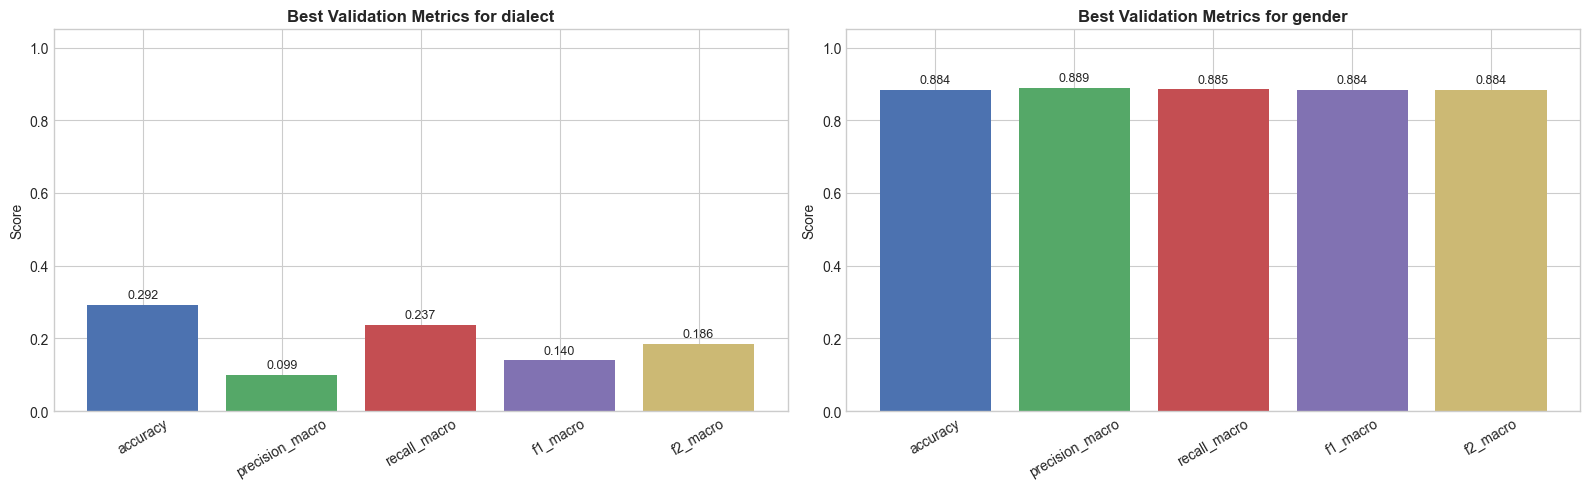

Saved: Results\Final Summary\classification_best_models_metrics.png


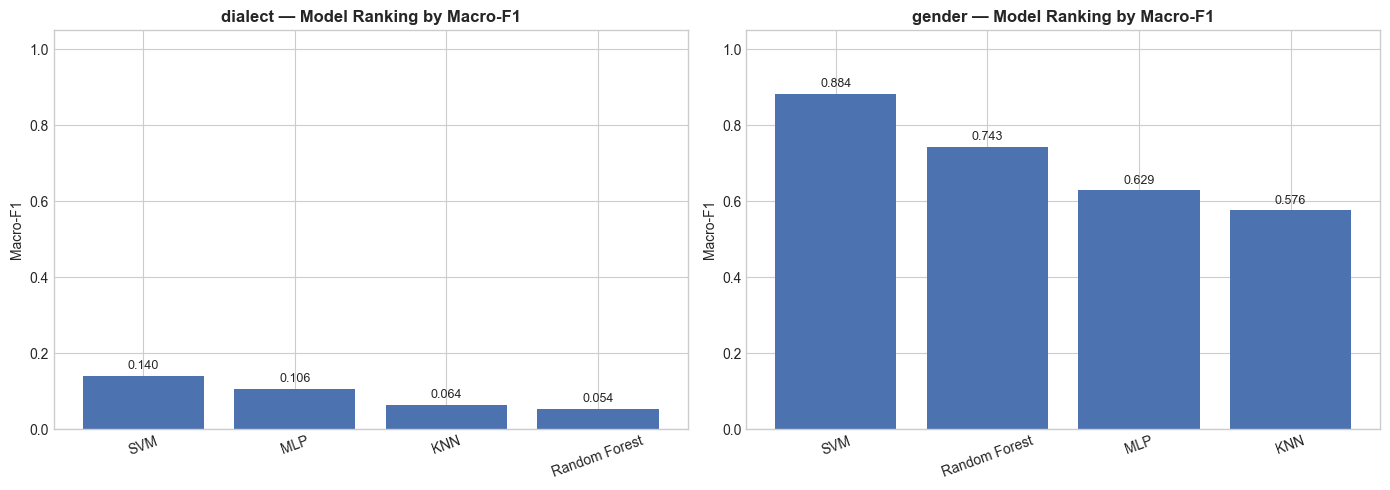

Saved: Results\Final Summary\classification_model_rankings_f1.png


## 2. Final Summary of Clustering Results

### Unsupervised Silhouette-Based Clustering Results

,Model,Selection,k,Silhouette,ARI Dialect,NMI Dialect,ARI Gender,NMI Gender
0,K-Means,Unsupervised silhouette-based k,10,0.1803,0.1652,0.3848,0.1620,0.3242
1,GMM,Unsupervised silhouette-based k,10,0.1761,0.1635,0.3760,0.1557,0.3140
2,Hierarchical,Unsupervised silhouette-based k,10,0.1633,0.1543,0.3639,0.1523,0.3070


Saved: Results\Final Summary\clustering_summary_unsupervised.csv


### Clustering Results Using Actual Number of Dialects

,Model,Selection,k,Silhouette,ARI Dialect,NMI Dialect,ARI Gender,NMI Gender
0,K-Means,Comparison using actual dialect count,5,0.1468,0.1664,0.2679,0.1900,0.2101
1,GMM,Comparison using actual dialect count,5,0.1418,0.1998,0.2926,0.1995,0.2766
2,Hierarchical,Comparison using actual dialect count,5,0.1263,0.1190,0.2343,0.2025,0.2474


Saved: Results\Final Summary\clustering_summary_true_k.csv
Saved: Results\Final Summary\clustering_summary_combined.csv


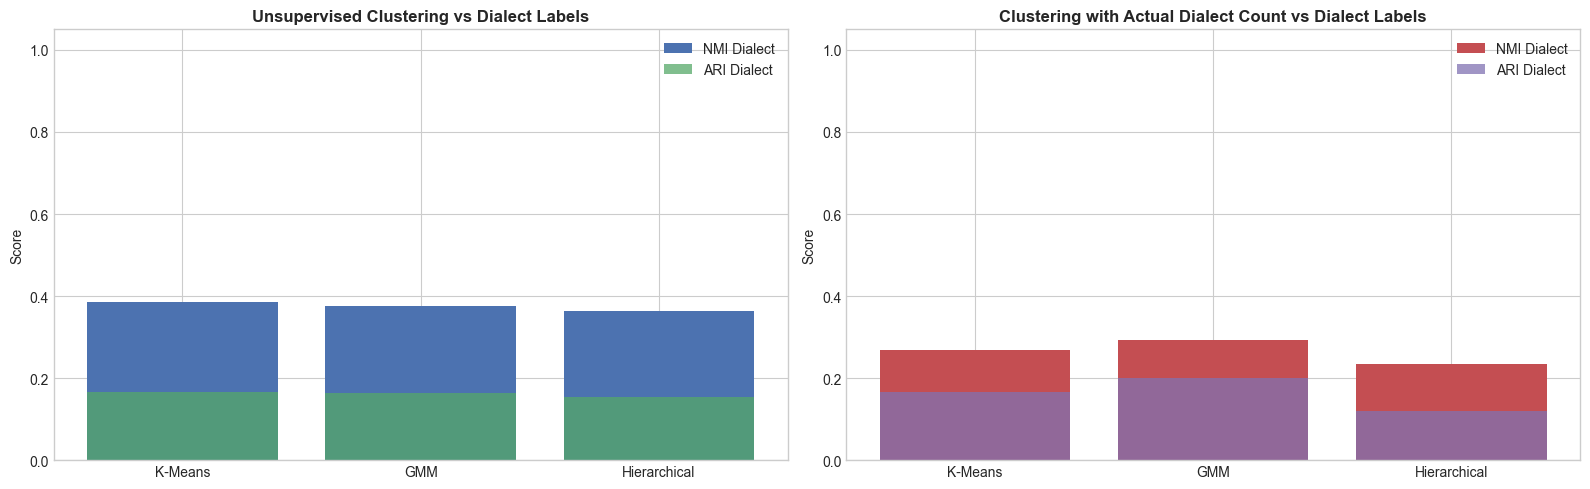

Saved: Results\Final Summary\clustering_dialect_alignment.png


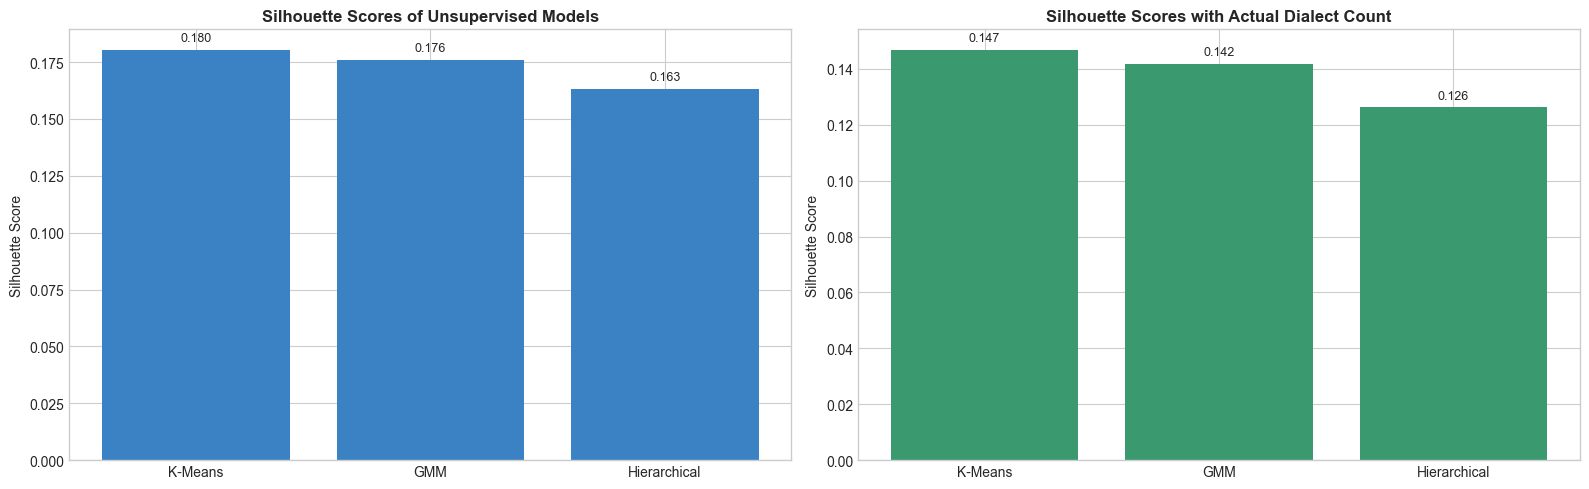

Saved: Results\Final Summary\clustering_silhouette_comparison.png


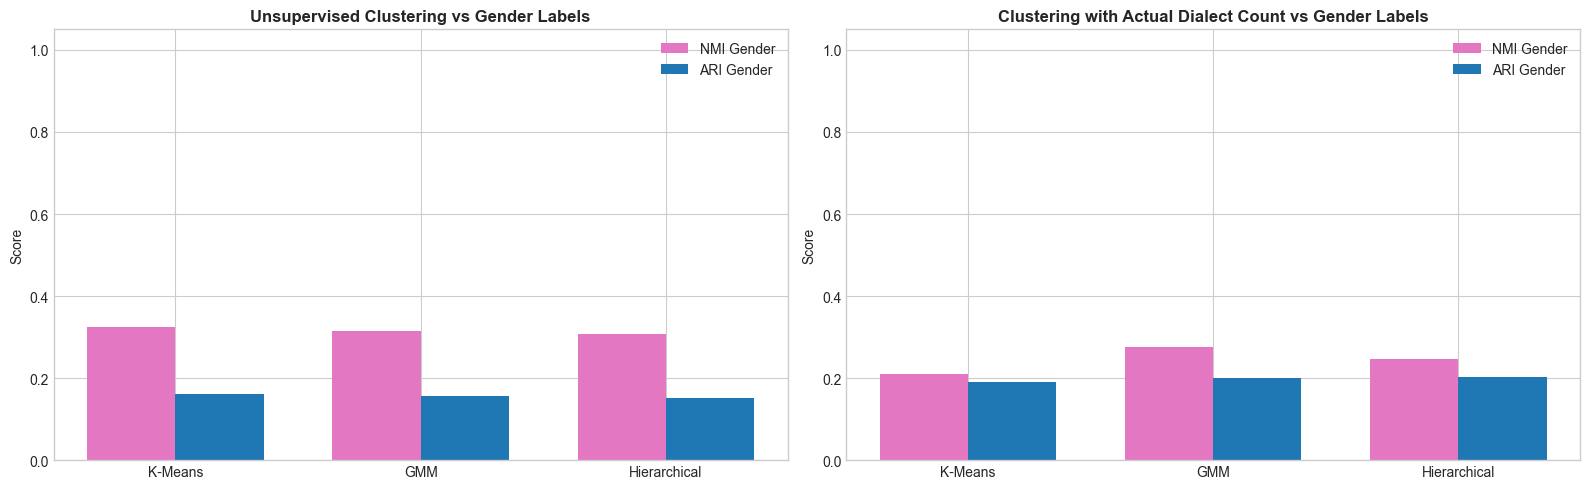

Saved: Results\Final Summary\clustering_gender_alignment.png


## 3. Integrated Final Interpretation

,task_type,task_name,selected_model,selection_basis,primary_score_name,primary_score_value,secondary_score_name,secondary_score_value
0,Classification,dialect,SVM,Best validation macro-F1,f1_macro,0.1397,accuracy,0.2923
1,Classification,gender,SVM,Best validation macro-F1,f1_macro,0.8838,accuracy,0.8841
2,Clustering,Best unsupervised clustering,K-Means,Highest NMI with dialect labels among silhouet...,NMI Dialect,0.3848,Silhouette,0.1803
3,Clustering,Best clustering with actual dialect count,GMM,Highest NMI with dialect labels when k equals ...,NMI Dialect,0.2926,Silhouette,0.1418


Saved: Results\Final Summary\final_interpretation_summary.csv


## 4. Final Narrative Summary

- For dialect classification, the best validation model was 'SVM' with macro-F1=0.1397 and accuracy=0.2923.
- For gender classification, the best validation model was 'SVM' with macro-F1=0.8838 and accuracy=0.8841.
- Among silhouette-based unsupervised clustering models, the best dialect-aligned model was 'K-Means' with k=10, NMI Dialect=0.3848, ARI Dialect=0.1652, and Silhouette=0.1803.
- When the number of clusters was fixed to the real number of dialects, the best model was 'GMM' with NMI Dialect=0.2926, ARI Dialect=0.1998, and Silhouette=0.1418.

Saved: Results\Final Summary\final_narrative_summary.txt

Cell 11 completed successfully.


In [15]:
print("="*100)
print("CELL 11 — FINAL STATISTICAL SUMMARY OF CLASSIFICATION AND CLUSTERING RESULTS")
print("=" * 100)

plt.style.use("seaborn-v0_8-whitegrid")

def section_title(text):
    display(Markdown(f"## {text}"))

def subsection_title(text):
    display(Markdown(f"### {text}"))

def format_numeric_df(df,digits=4):
    display_df=df.copy()
    numeric_cols =display_df.select_dtypes(include=[np.number]).columns

    for col in numeric_cols:
        display_df[col]=display_df[col].round(digits)

    return display_df

def save_dataframe(df, filename):
    path=os.path.join(FINAL_SUMMARY_DIR,filename)
    df.to_csv(path,index=False)
    return path

def add_value_labels(ax,fmt="{:.3f}",rotation=0,fontsize=9):
    for p in ax.patches:
        h=p.get_height()
        if pd.notna(h):
            ax.annotate(fmt.format(h),(p.get_x()+p.get_width()/2,h),ha="center",va="bottom",fontsize=fontsize,rotation=rotation,xytext=(0,4),textcoords="offset points")

section_title("1. Final Summary of Classification Results")

if len(classification_outputs)==0:
    print("No classification results are available.")
else:
    classification_summary_rows=[]

    for target, output in classification_outputs.items():
        task_results=output["results"].copy().reset_index()
        task_results =task_results.rename(columns={"index":"model"})
        task_results["target"]=target
        classification_summary_rows.append(task_results)

    classification_all_results_df=pd.concat(classification_summary_rows,ignore_index=True)

    ordered_cols=["target","model","accuracy","precision_macro","recall_macro","f1_macro","f2_macro"]
    classification_all_results_df=classification_all_results_df[ordered_cols]

    subsection_title("All Validation Results for Classification Models")
    display(format_numeric_df(classification_all_results_df.sort_values(["target","f1_macro"],ascending=[True,False])))

    classification_all_results_path=save_dataframe(classification_all_results_df,"classification_all_validation_results.csv")
    print(f"Saved: {classification_all_results_path}")

    subsection_title("Best Model per Classification Task")
    display(format_numeric_df(final_summary_df))

    final_summary_path =save_dataframe(final_summary_df,"classification_best_models_summary.csv")
    print(f"Saved: {final_summary_path}")

    fig,axes=plt.subplots(1,2,figsize=(16,5))

    metric_cols=["accuracy","precision_macro","recall_macro","f1_macro","f2_macro"]

    for ax,(_,row) in zip(axes,final_summary_df.iterrows()):
        task=row["target"]
        values=[row[m] for m in metric_cols]

        bars=ax.bar(metric_cols,values,color=["#4C72B0","#55A868","#C44E52","#8172B2","#CCB974"])
        ax.set_ylim(0,1.05)
        ax.set_title(f"Best Validation Metrics for {task}",fontsize=12,fontweight="bold")
        ax.set_ylabel("Score")
        ax.tick_params(axis="x",rotation=30)

        for bar,value in zip(bars,values):
            ax.text(bar.get_x()+bar.get_width()/2,value+0.01,f"{value:.3f}",ha="center",va="bottom",fontsize=9)

    plt.tight_layout()
    best_cls_metrics_plot=os.path.join(FINAL_SUMMARY_DIR,"classification_best_models_metrics.png")
    plt.savefig(best_cls_metrics_plot,dpi=300,bbox_inches="tight")
    plt.show()
    print(f"Saved: {best_cls_metrics_plot}")

    fig, axes=plt.subplots(1,len(classification_outputs),figsize=(7*len(classification_outputs),5))

    if len(classification_outputs)==1:
        axes=[axes]

    for ax,(target,output) in zip(axes,classification_outputs.items()):
        task_df=output["results"].copy().reset_index()
        task_df =task_df.rename(columns={"index":"model"})
        task_df=task_df.sort_values("f1_macro",ascending=False)

        bars=ax.bar(task_df["model"],task_df["f1_macro"],color="#4C72B0")
        ax.set_ylim(0,1.05)
        ax.set_title(f"{target} — Model Ranking by Macro-F1",fontsize=12,fontweight="bold")
        ax.set_ylabel("Macro-F1")
        ax.tick_params(axis="x",rotation=20)

        for bar,value in zip(bars,task_df["f1_macro"]):
            ax.text(bar.get_x()+bar.get_width()/2,value+0.01,f"{value:.3f}",ha="center",va="bottom",fontsize=9)

    plt.tight_layout()
    cls_rank_plot =os.path.join(FINAL_SUMMARY_DIR,"classification_model_rankings_f1.png")
    plt.savefig(cls_rank_plot,dpi=300,bbox_inches="tight")
    plt.show()
    print(f"Saved: {cls_rank_plot}")

section_title("2. Final Summary of Clustering Results")

if ("summary_unsupervised" not in globals()) or ("summary_true_k" not in globals()):
    print("Clustering summary tables are not available.")
else:
    subsection_title("Unsupervised Silhouette-Based Clustering Results")
    display(format_numeric_df(summary_unsupervised))

    path_unsup=save_dataframe(summary_unsupervised,"clustering_summary_unsupervised.csv")
    print(f"Saved: {path_unsup}")

    subsection_title("Clustering Results Using Actual Number of Dialects")
    display(format_numeric_df(summary_true_k))

    path_truek =save_dataframe(summary_true_k,"clustering_summary_true_k.csv")
    print(f"Saved: {path_truek}")

    combined_clustering_summary=pd.concat([summary_unsupervised,summary_true_k],axis=0,ignore_index=True)

    combined_path=save_dataframe(combined_clustering_summary,"clustering_summary_combined.csv")
    print(f"Saved: {combined_path}")

    fig,axes=plt.subplots(1,2,figsize=(16,5))

    plot_df_unsup=summary_unsupervised.copy()
    plot_df_true =summary_true_k.copy()

    axes[0].bar(plot_df_unsup["Model"],plot_df_unsup["NMI Dialect"],color="#4C72B0",label="NMI Dialect")
    axes[0].bar(plot_df_unsup["Model"],plot_df_unsup["ARI Dialect"],color="#55A868",alpha=0.75,label="ARI Dialect")
    axes[0].set_title("Unsupervised Clustering vs Dialect Labels",fontsize=12,fontweight="bold")
    axes[0].set_ylabel("Score")
    axes[0].set_ylim(0,1.05)
    axes[0].legend()

    axes[1].bar(plot_df_true["Model"],plot_df_true["NMI Dialect"],color="#C44E52",label="NMI Dialect")
    axes[1].bar(plot_df_true["Model"],plot_df_true["ARI Dialect"],color="#8172B2",alpha=0.75,label="ARI Dialect")
    axes[1].set_title("Clustering with Actual Dialect Count vs Dialect Labels",fontsize=12,fontweight="bold")
    axes[1].set_ylabel("Score")
    axes[1].set_ylim(0,1.05)
    axes[1].legend()

    plt.tight_layout()
    clustering_dialect_plot=os.path.join(FINAL_SUMMARY_DIR,"clustering_dialect_alignment.png")
    plt.savefig(clustering_dialect_plot,dpi=300,bbox_inches="tight")
    plt.show()
    print(f"Saved: {clustering_dialect_plot}")

    fig,axes=plt.subplots(1,2,figsize=(16,5))

    bars1=axes[0].bar(summary_unsupervised["Model"],summary_unsupervised["Silhouette"],color="#3B82C4")
    axes[0].set_title("Silhouette Scores of Unsupervised Models",fontsize=12,fontweight="bold")
    axes[0].set_ylabel("Silhouette Score")
    add_value_labels(axes[0],fmt="{:.3f}")

    bars2 =axes[1].bar(summary_true_k["Model"],summary_true_k["Silhouette"],color="#3B9970")
    axes[1].set_title("Silhouette Scores with Actual Dialect Count",fontsize=12,fontweight="bold")
    axes[1].set_ylabel("Silhouette Score")
    add_value_labels(axes[1],fmt="{:.3f}")

    plt.tight_layout()
    clustering_sil_plot=os.path.join(FINAL_SUMMARY_DIR,"clustering_silhouette_comparison.png")
    plt.savefig(clustering_sil_plot,dpi=300,bbox_inches="tight")
    plt.show()
    print(f"Saved: {clustering_sil_plot}")

    fig, axes=plt.subplots(1,2,figsize=(16,5))

    x=np.arange(len(summary_unsupervised["Model"]))
    width =0.36

    axes[0].bar(x-width/2,summary_unsupervised["NMI Gender"],width=width,color="#E377C2",label="NMI Gender")
    axes[0].bar(x+width/2,summary_unsupervised["ARI Gender"],width=width,color="#1F77B4",label="ARI Gender")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(summary_unsupervised["Model"])
    axes[0].set_ylim(0,1.05)
    axes[0].set_title("Unsupervised Clustering vs Gender Labels",fontsize=12,fontweight="bold")
    axes[0].set_ylabel("Score")
    axes[0].legend()

    x2 =np.arange(len(summary_true_k["Model"]))

    axes[1].bar(x2-width/2,summary_true_k["NMI Gender"],width=width,color="#E377C2",label="NMI Gender")
    axes[1].bar(x2+width/2,summary_true_k["ARI Gender"],width=width,color="#1F77B4",label="ARI Gender")
    axes[1].set_xticks(x2)
    axes[1].set_xticklabels(summary_true_k["Model"])
    axes[1].set_ylim(0,1.05)
    axes[1].set_title("Clustering with Actual Dialect Count vs Gender Labels",fontsize=12,fontweight="bold")
    axes[1].set_ylabel("Score")
    axes[1].legend()

    plt.tight_layout()
    clustering_gender_plot =os.path.join(FINAL_SUMMARY_DIR,"clustering_gender_alignment.png")
    plt.savefig(clustering_gender_plot,dpi=300,bbox_inches="tight")
    plt.show()
    print(f"Saved: {clustering_gender_plot}")

section_title("3. Integrated Final Interpretation")

final_interpretation_rows=[]

if len(classification_outputs)>0:
    for _,row in final_summary_df.iterrows():
        final_interpretation_rows.append({"task_type":"Classification","task_name":row["target"],"selected_model":row["best_model"],"selection_basis":"Best validation macro-F1","primary_score_name":"f1_macro","primary_score_value":row["f1_macro"],"secondary_score_name":"accuracy","secondary_score_value":row["accuracy"]})

if ("best_unsupervised_row" in globals()) and ("best_true_k_row" in globals()):
    final_interpretation_rows.append({"task_type":"Clustering","task_name":"Best unsupervised clustering","selected_model":best_unsupervised_row["Model"],"selection_basis":"Highest NMI with dialect labels among silhouette-based unsupervised models","primary_score_name":"NMI Dialect","primary_score_value":best_unsupervised_row["NMI Dialect"],"secondary_score_name":"Silhouette","secondary_score_value":best_unsupervised_row["Silhouette"]})

    final_interpretation_rows.append({"task_type":"Clustering","task_name":"Best clustering with actual dialect count","selected_model":best_true_k_row["Model"],"selection_basis":"Highest NMI with dialect labels when k equals the true number of dialects","primary_score_name":"NMI Dialect","primary_score_value":best_true_k_row["NMI Dialect"],"secondary_score_name":"Silhouette","secondary_score_value":best_true_k_row["Silhouette"]})

final_interpretation_df=pd.DataFrame(final_interpretation_rows)

display(format_numeric_df(final_interpretation_df,digits=4))

final_interpretation_path =save_dataframe(final_interpretation_df,"final_interpretation_summary.csv")
print(f"Saved: {final_interpretation_path}")

section_title("4. Final Narrative Summary")

summary_lines=[]

if len(classification_outputs)>0:
    for _,row in final_summary_df.iterrows():
        summary_lines.append(f"- For {row['target']} classification, the best validation model was '{row['best_model']}' with macro-F1={row['f1_macro']:.4f} and accuracy={row['accuracy']:.4f}.")

if ("best_unsupervised_row" in globals()) and ("best_true_k_row" in globals()):
    summary_lines.append(f"- Among silhouette-based unsupervised clustering models, the best dialect-aligned model was '{best_unsupervised_row['Model']}' with k={int(best_unsupervised_row['k'])}, NMI Dialect={best_unsupervised_row['NMI Dialect']:.4f}, ARI Dialect={best_unsupervised_row['ARI Dialect']:.4f}, and Silhouette={best_unsupervised_row['Silhouette']:.4f}.")

    summary_lines.append(f"- When the number of clusters was fixed to the real number of dialects, the best model was '{best_true_k_row['Model']}' with NMI Dialect={best_true_k_row['NMI Dialect']:.4f}, ARI Dialect={best_true_k_row['ARI Dialect']:.4f}, and Silhouette={best_true_k_row['Silhouette']:.4f}.")

summary_md="\n".join(summary_lines) if summary_lines else "No final summary could be generated."

display(Markdown(summary_md))

with open(os.path.join(FINAL_SUMMARY_DIR,"final_narrative_summary.txt"),"w",encoding="utf-8") as f:
    f.write(summary_md)

print(f"Saved: {os.path.join(FINAL_SUMMARY_DIR,'final_narrative_summary.txt')}")
print("\nCell 11 completed successfully.")
